# K-Nearest Neighbors | Nearest Centroid Classifier: Comparing and Evaluating Performances



### **Purpose**

In this particular project we aim to calculate the performances of some of the
most widely known (mostly in the scientific community) computational classification algorithms, and more explicitly: the K-Nearest Neighbors method and the Nearest Centroid Classifier. The foretold evaluations will be implemented using a dataset of our choice, and everything regarding the coding part will be implemented in Python. As for the hardware, we will use Google Colab's T4 GPU so the running times may vary in each attempt.

#


### **About NCC and K-NN**


*  ***K-NN*** : A simple algorithm used in supervised machine learning for classification or regression tasks (in this project it is used for classification). It is based on the idea that the points (observations) closest to a given data point are the most "similar" observations in a data set, and we can therefore classify unforeseen points based on the values of the closest existing points. By choosing K (number of neighbors), we can select the number of nearby observations to use in the algorithm.


*  ***NCC*** : Also a simple algorithm used in supervised machine learning for classification. Given a data point (observation), the Nearest Centroid Classifier simply assigns it the label (class) of the training sample whose mean or centroid is closest to it.



#


### **Chosen Dataset**
The dataset used for this project is the CIFAR-10 dataset (taken from the following adress https://www.cs.toronto.edu/~kriz/cifar.html) and consists of 60.000 32x32 colour images in 10 classes (6.000 pics for each). It is divided into five training batches, each including 10.000 pictures in random order, and a test batch that contains 10.000 randomly-selected images from each class. Some training batches may contain more images from one class than another. The classes are completely mutually exclusive, and are the following: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck.

#



### **Intermediate Project's Layout**
The project is mainly structured in the following order (sections):


1. Imported modules' description,
2. Implementation of K-NN and NCC,
3. Implementation of additional utility functions,
4. Loading the dataset and standardizing features,
5. Training and evaluating K-NN and NCC,
6. Main comparison summary



## **1\. Imported Modules' Description**


The modules we will be using throughout the intermediate project are the following:



*  ***numpy*** : More precisely a library used for working with arrays which are way faster to process than lists. We treat the train and test data as arrays.
*  ***time*** : We use certain functions of this module in order to measure the training and pediction time of each method.
*  ***collections*** : We use the Counter() method in K-NN to determine which class label appears more frequently among the k neighbors of a test point.
*  ***pickle*** : CIFAR-10 dataset files are saved as pickled Python dictionaries. We convert the binary file back into a Python dictionary.
*  ***urllib*** : We automatically download the CIFAR-10 dataset from the URL (imported locally into download_cifar10()).
*  ***tarfile*** : CIFAR-10 is distributed as a .tar.gz file, so we need the module to extract the files (imported locally into download_cifar10()).

The related code follows:




In [ ]:
import numpy as np
import time
from collections import Counter
import pickle

## **2. Implementation of K-NN and NCC**

In the fisrt part of the current section, we code the K- Nearest Neighbors algorithm from scratch. Instances of each class will be used later to train the models. We begin by declaring a class named KNNClassifier in which the following methods are defined:



*  Initialization function **\__init\__(self, k=3)**, where k the number of nearest neighbors with default value 3.
*  ***fit(self, X, y)***, where X is the training data features parameter and y the training data labels parameter. It essentially stores the training data.
*  ***euclidean_distance(self, x1, x2)***, where x1 and x2 are points in n-dimensional space. It calculates the distance between two points, so  the nearest neighbors to an entry point will be pinpointed through the various distances.
*  ***predict_single_sample(self, x)***, where x is a single data sample. It predicts the class label for sample x by calculating the distance between it and the training samples.

*  ***predict_multiple_samples(self, X)***, where X are multiple samples. It implements the same function as *predict_single_sample(self, x)* but for more samples.

*  ***accuracy_score(self, X, y)***, where X the test samples and y the true labels. It calculates the accuracy of the predictions, where accuracy = (TN + TP) / (TP + TN + FP + FN)

The related code follows:




In [ ]:
# ==============================================
# KNN CLASSIFIER
# ==============================================

class KNNClassifier:
    """K-Nearest Neighbors Classifier"""

    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)
        return self

    def euclidean_distance(self, x1, x2):
        return np.sqrt(np.sum((x1 - x2) ** 2))

    def predict_single_sample(self, x):
        # Calculate distances
        distances = []
        for i in range(len(self.X_train)):
            dist = self.euclidean_distance(x, self.X_train[i])
            distances.append((dist, self.y_train[i]))

        # Sort the distances to find the k nearest neighbors
        distances.sort()
        k_nearest = distances[:self.k]

        # Extract the labels of the k nearest neighbors
        k_nearest_labels = [label for _, label in k_nearest]

        # Return the most common label
        most_common = Counter(k_nearest_labels).most_common(1)
        return most_common[0][0]

    def predict_multiple_samples(self, X):
        X = np.array(X)
        predictions = [self.predict_single_sample(x) for x in X]
        return np.array(predictions)

    def accuracy_score(self, X, y):
        predictions = self.predict_multiple_samples(X)
        accuracy = np.sum(predictions == y) / len(y) if len(y) > 0 else 0
        return accuracy

In the second part of the current section, we code the Nearest Centroid Classifier algorithm from scratch. We begin by declaring a class named NCCClassifier in which the following methods are defined:



*  Initialization function **\__init(self)\__**.

*  ***fit(self, X, y)***, where X array of training data features and y array of training data labels. It trains the NCC classifier by calculating the centroid for each class.

*  ***euclidean_distance(self, point1, point2)***, where point1 and point2 (arrays) points in n-dimensional space. It calculates the euclidean distance between two points.

*  ***predict_single_sample(self, x)***, where x (array) a single sample to classify. It finds the nearest class centroid and returns the class label.

*  ***predict_single_sample(self, x)***, where X (array) multiple samples to classify. It predicts class labels for multiple samples.

*  ***accuracy_score(self, X, y)***, where X (array) test samples and y (array) true labels.  It calculates the classification accuracy, where accuracy = (TN + TP) / (TP + TN + FP + FN)

*  ***get_centroids(self)***, which returns the calculated centroids of all classes in dictionary form.

The related code follows:

In [ ]:
# ==============================================
# NCC CLASSIFIER
# ==============================================

class NCCClassifier:

    def __init__(self):
        self.centroids = {} # Dictionary to store centroid for each class
        self.classes = None # Will store unique class labels

    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y)

        # Get all unique class labels
        self.classes = np.unique(y)

        # Calculate centroid for each class
        for class_label in self.classes:
            # Get all samples belonging to this class
            class_samples = X[y == class_label]

            if class_samples.shape[0] > 0:
                # Calculate mean(class centroid) of all features
                centroid = np.mean(class_samples, axis=0)
                self.centroids[class_label] = centroid

        return self

    def euclidean_distance(self, point1, point2):
        return np.sqrt(np.sum((point1 - point2) ** 2))

    def predict_single_sample(self, x):

        # Calculate distance from sample to each class centroid
        distances = {}
        for class_label, centroid in self.centroids.items():
            dist = self.euclidean_distance(x, centroid)
            distances[class_label] = dist

        # Return the class with minimum distance
        nearest_class = min(distances, key=distances.get)
        return nearest_class

    def predict_multiple_samples(self, X):
        X = np.array(X)
        predictions = [self.predict_single_sample(x) for x in X]
        return np.array(predictions)

    def accuracy_score(self, X, y):
        predictions = self.predict_multiple_samples(X)
        accuracy = np.sum(predictions == y) / len(y) if len(y) > 0 else 0
        return accuracy

    def get_centroids(self):
        return self.centroids

## **3. Implementation of Additional Utility Functions**

In the specific section, we give a description of each of the functions that are needed in order to draw cocnlusions for the methods' performances. We code the following:



*  ***standardize(X_train, X_test)***, where X_train (array) training data to calculate mean/std from, and X_test test data to transform using training statistics. It standardizes features by removing mean and scaling to unit variance. This ensures all features have  mean=0 and std=1.

*  ***confusion_matrix(y_true, y_pred)***, where y_true (array) true class labels, and y_pred (array) predicted class labels. It calculates the confusion matrix which shows how many samples were correctly/incorrectly classified. Rows represent true labels, columns represent predicted labels.

*  ***calculate_metrics(conf_matrix)***, which calculates performance metrics from confusion matrix. Specifically: accuracy, precision, recall, F1-score and specificity.

The related code follows:



In [ ]:
# ============================================================================
# UTILITY FUNCTIONS
# ============================================================================

def standardize(X_train, X_test):
    """Standardize features"""

    # Calculate mean and standard deviation from training data only
    mean = np.mean(X_train, axis=0)
    std = np.std(X_train, axis=0)

    # Avoid division by zero, set std=1
    std[std == 0] = 1

    # Apply standardization to both training and test data
    X_train_scaled = (X_train - mean) / std
    X_test_scaled = (X_test - mean) / std

    return X_train_scaled, X_test_scaled


def confusion_matrix(y_true, y_pred):
    """Calculate confusion matrix for multi-class"""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Get all unique classes from both true and predicted labels
    classes = np.unique(np.concatenate([y_true, y_pred]))
    n_classes = len(classes)

    # Initialize confusion matrix with zeros
    conf_mat = np.zeros((n_classes, n_classes), dtype=int)

    # Create mapping from class labels to matrix indices
    class_to_index = {cls: i for i, cls in enumerate(classes)}

    # Fill confusion matrix by counting predictions
    for true_label, pred_label in zip(y_true, y_pred):
        true_index = class_to_index[true_label]
        pred_index = class_to_index[pred_label]
        conf_mat[true_index, pred_index] += 1

    return conf_mat


def calculate_metrics(conf_matrix):
    """Calculate metrics from confusion matrix"""

    # Calculate overall accuracy
    total_samples = np.sum(conf_matrix)
    accuracy = np.trace(conf_matrix) / total_samples if total_samples > 0 else 0

    # Calculate per-class metrics and average them
    n_classes = conf_matrix.shape[0]
    precisions = []
    recalls = []
    f1_scores = []

    for i in range(n_classes):
        # For each class, calculate TP, FP, FN
        tp = conf_matrix[i, i]
        fp = np.sum(conf_matrix[:, i]) - tp
        fn = np.sum(conf_matrix[i, :]) - tp

        # Calculate per-class metrics
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0

        precisions.append(prec)
        recalls.append(rec)
        f1_scores.append(f1)

    # Average of per-class metrics
    precision = np.mean(precisions) if precisions else 0
    recall = np.mean(recalls) if recalls else 0
    f1_score = np.mean(f1_scores) if f1_scores else 0
    specificity = 0

    return accuracy, precision, recall, f1_score, specificity

## **4. Loading the Dataset and Standardizing Features**

In section four, we defined a function named ***download_cifar-10()*** to automatically download from the source and extract the dataset. It returns a tuple consisting of the train files (5 batch file paths) and the test files (1 batch file path). Afterwards, we make use of the foretold function and load all batches of the dataset into our code and, for the final part, we standardize the dataset's features using the previously function ***standardize(X_train, X_test)***. We also locally import modules **tarfile** and **urllib.request**.

The related code follows:

In [ ]:
def download_cifar10():
    """Automatically download and extract CIFAR-10 dataset"""

    # Import required modules for downloading and extracting
    import urllib.request
    import tarfile

    print("\n Downloading CIFAR-10 dataset...")

    # Official CIFAR-10 download URL
    url = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
    filename = "cifar-10-python.tar.gz"

    # Download the dataset file from the internet
    print("  Downloading...")
    urllib.request.urlretrieve(url, filename)
    print("   Downloaded successfully!")

    # Extract the compressed archive to get all batch files
    print("  Extracting files...")
    with tarfile.open(filename, "r:gz") as tar:
        tar.extractall()  # Extracts to cifar-10-batches-py/ folder
    print("   Extracted successfully!")

    # Define paths to all 5 training batch files (10,000 images each)
    train_files = [
        "cifar-10-batches-py/data_batch_1",
        "cifar-10-batches-py/data_batch_2",
        "cifar-10-batches-py/data_batch_3",
        "cifar-10-batches-py/data_batch_4",
        "cifar-10-batches-py/data_batch_5"
    ]

    # Define path to test batch file (10,000 images)
    test_file = "cifar-10-batches-py/test_batch"

    return train_files, test_file

# ============================================================================
# LOAD DATASET - AUTO-DOWNLOAD CIFAR-10
# ============================================================================

def unpickle(file):
    """Unpickle data files"""
    with open(file, 'rb') as fo:
        dict = pickle.load(fo, encoding='bytes')
    return dict

print("\n" + "="*80)
print("LOADING CIFAR-10 DATASET")
print("="*80)

# Auto-download CIFAR-10 dataset
TRAIN_FILES, TEST_FILE = download_cifar10()

# Load all training batches
print(f"\nLoading all training batches (50,000 samples)...")
X_train_list = []
y_train_list = []

for i, train_file in enumerate(TRAIN_FILES, 1):
    print(f"  Loading batch {i}/5: {train_file}")
    train_data = unpickle(train_file)

    # Load data
    if b'data' in train_data:
        X_batch = np.array(train_data[b'data'], dtype=np.float64)
    else:
        X_batch = np.array(train_data['data'], dtype=np.float64)

    # Load labels
    if b'labels' in train_data:
        y_batch = np.array(train_data[b'labels'])
    else:
        y_batch = np.array(train_data['labels'])

    X_train_list.append(X_batch)
    y_train_list.append(y_batch)

# Concatenate all training batches
X_train = np.vstack(X_train_list)
y_train = np.hstack(y_train_list)

print(f"   All training batches loaded!")

# Load test data
print(f"\nLoading test data from: {TEST_FILE}")

test_data = unpickle(TEST_FILE)

# Load test data
if b'data' in test_data:
    X_test = np.array(test_data[b'data'], dtype=np.float64)
else:
    X_test = np.array(test_data['data'], dtype=np.float64)

# Load test labels
if b'labels' in test_data:
    y_test = np.array(test_data[b'labels'])
else:
    y_test = np.array(test_data['labels'])

print(" Successfully loaded data!")

print(f"\nDataset shapes:")
print(f"  X_train shape: {X_train.shape}")
print(f"  y_train shape: {y_train.shape}")
print(f"  X_test shape: {X_test.shape}")
print(f"  y_test shape: {y_test.shape}")

# Ensure labels are 1D
if y_train.ndim > 1:
    y_train = y_train.flatten()
if y_test.ndim > 1:
    y_test = y_test.flatten()

print(f"\nFinal dataset information:")
print(f"  Training samples: {X_train.shape[0]}")
print(f"  Testing samples: {X_test.shape[0]}")
print(f"  Features per sample: {X_train.shape[1]}")
print(f"  Number of classes: {len(np.unique(y_train))}")

# ============================================================================
# STANDARDIZE FEATURES
# ============================================================================

print("\n" + "="*80)
print("PREPROCESSING")
print("="*80)
print("\nStandardizing features...")
X_train_scaled, X_test_scaled = standardize(X_train, X_test)

print(f"\nStandardized dataset:")
print(f"  Training samples: {X_train_scaled.shape[0]}")
print(f"  Testing samples: {X_test_scaled.shape[0]}")
print(f"  Number of features: {X_train_scaled.shape[1]}")
print(f"  Unique classes in y_train: {len(np.unique(y_train))}")
print(f"  Unique classes in y_test: {len(np.unique(y_test))}")

# Store results
results = {}


LOADING CIFAR-10 DATASET

  Downloading...
   Downloaded successfully!
  Extracting files...


/tmp/ipython-input-1188192282.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()  # Extracts to cifar-10-batches-py/ folder


   Extracted successfully!

Loading all training batches (50,000 samples)...
  Loading batch 1/5: cifar-10-batches-py/data_batch_1
  Loading batch 2/5: cifar-10-batches-py/data_batch_2
  Loading batch 3/5: cifar-10-batches-py/data_batch_3
  Loading batch 4/5: cifar-10-batches-py/data_batch_4
  Loading batch 5/5: cifar-10-batches-py/data_batch_5
   All training batches loaded!

Loading test data from: cifar-10-batches-py/test_batch
Available keys in test file: [b'batch_label', b'labels', b'data', b'filenames']
 Successfully loaded data!

Dataset shapes:
  X_train shape: (50000, 3072)
  y_train shape: (50000,)
  X_test shape: (10000, 3072)
  y_test shape: (10000,)

Final dataset information:
  Training samples: 50000
  Testing samples: 10000
  Features per sample: 3072
  Number of classes: 10

PREPROCESSING

Standardizing features...

Standardized dataset:
  Training samples: 50000
  Testing samples: 10000
  Number of features: 3072
  Unique classes in y_train: 10
  Unique classes in y_t

## **5. Training and evaluating K-NN and NCC**

In the first part of this section, we train the NCC method and store the results of it's perfromance so that we can use them later for comparison.

The related code follows:

In [ ]:
# ========================================================================
# Train and evaluate NCC
# ========================================================================

print("\n" + "="*80)
print("NEAREST CENTROID CLASSIFIER (NCC)")
print("="*80)

start_time = time.time()
ncc = NCCClassifier()
ncc.fit(X_train_scaled, y_train)
train_time_ncc = time.time() - start_time

start_time = time.time()
y_pred_ncc = ncc.predict_multiple_samples(X_test_scaled)
predict_time_ncc = time.time() - start_time

conf_mat_ncc = confusion_matrix(y_test, y_pred_ncc)
acc_ncc, prec_ncc, rec_ncc, f1_ncc, spec_ncc = calculate_metrics(conf_mat_ncc)

results['NCC'] = {
    'accuracy': acc_ncc,
    'precision': prec_ncc,
    'recall': rec_ncc,
    'f1_score': f1_ncc,
    'specificity': spec_ncc,
    'train_time': train_time_ncc,
    'predict_time': predict_time_ncc,
    'confusion_matrix': conf_mat_ncc
}

print(f"\nPerformance Metrics:")
print(f"  Accuracy:    {acc_ncc*100:.2f}%")
print(f"  Precision:   {prec_ncc:.3f}")
print(f"  Recall:      {rec_ncc:.3f}")
print(f"  F1-Score:    {f1_ncc:.3f}")


print(f"\nTiming:")
print(f"  Training time:   {train_time_ncc*1000:.2f} ms")
print(f"  Prediction time: {predict_time_ncc*1000:.2f} ms")
print(f"  Avg per sample:  {predict_time_ncc/len(X_test)*1000:.3f} ms" if len(X_test) > 0 else "Avg per sample: N/A")

print(f"\nConfusion Matrix shape: {conf_mat_ncc.shape}")


NEAREST CENTROID CLASSIFIER (NCC)

Performance Metrics:
  Accuracy:    28.12%
  Precision:   0.293
  Recall:      0.281
  F1-Score:    0.259

Timing:
  Training time:   900.41 ms
  Prediction time: 1123.94 ms
  Avg per sample:  0.112 ms

Confusion Matrix shape: (10, 10)


In the second part of this section, we train the K-NN classifier and store the results of it's perfromance so that we can use them later for comparison. Training and evaluation will take place for k=1 and k=3.

The related code follows:

In [ ]:
# ========================================================================
# Train and evaluate KNN with k=1 and k=3
# ========================================================================

k_values = [1, 3]

for k in k_values:
    print("\n" + "="*80)
    print(f"K-NEAREST NEIGHBORS (K={k})")
    print("="*80)

    start_time = time.time()
    knn = KNNClassifier(k=k)
    knn.fit(X_train_scaled, y_train)
    train_time_knn = time.time() - start_time

    start_time = time.time()
    y_pred_knn = knn.predict_multiple_samples(X_test_scaled)
    predict_time_knn = time.time() - start_time

    conf_mat_knn = confusion_matrix(y_test, y_pred_knn)
    acc_knn, prec_knn, rec_knn, f1_knn, spec_knn = calculate_metrics(conf_mat_knn)

    results[f'KNN_K{k}'] = {
        'accuracy': acc_knn,
        'precision': prec_knn,
        'recall': rec_knn,
        'f1_score': f1_knn,
        'specificity': spec_knn,
        'train_time': train_time_knn,
        'predict_time': predict_time_knn,
        'confusion_matrix': conf_mat_knn
    }

    print(f"\nPerformance Metrics:")
    print(f"  Accuracy:    {acc_knn*100:.2f}%")
    print(f"  Precision:   {prec_knn:.3f}")
    print(f"  Recall:      {rec_knn:.3f}")
    print(f"  F1-Score:    {f1_knn:.3f}")


    print(f"\nTiming:")
    print(f"  Training time:   {train_time_knn*1000:.2f} ms")
    print(f"  Prediction time: {predict_time_knn*1000:.2f} ms")
    print(f"  Avg per sample:  {predict_time_knn/len(X_test)*1000:.3f} ms" if len(X_test) > 0 else "Avg per sample: N/A")

    print(f"\nConfusion Matrix shape: {conf_mat_knn.shape}")


K-NEAREST NEIGHBORS (K=1)

Performance Metrics:
  Accuracy:    35.67%
  Precision:   0.415
  Recall:      0.357
  F1-Score:    0.352

Timing:
  Training time:   426.44 ms
  Prediction time: 6540556.19 ms
  Avg per sample:  654.056 ms

Confusion Matrix shape: (10, 10)

K-NEAREST NEIGHBORS (K=3)

Performance Metrics:
  Accuracy:    35.49%
  Precision:   0.421
  Recall:      0.355
  F1-Score:    0.348

Timing:
  Training time:   418.66 ms
  Prediction time: 6544985.92 ms
  Avg per sample:  654.499 ms

Confusion Matrix shape: (10, 10)


## **6. Main Comparison Summary**

In the final section of the intermediate project, we compare the performances between NCC and K-NN, for k=1 and k=3, in order to declare which of them is faster and more precise. The final results will be displayed of course once the whole code runs.

The related code follows:


In [ ]:
# ========================================================================
# COMPARISON SUMMARY
# ========================================================================

print("\n" + "="*80)
print(" "*25 + "COMPARISON SUMMARY")
print("="*80)

print(f"\n{'Model':<12} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'Time(ms)':<12}")
print("-"*80)

for model_name, metrics in results.items():
    print(f"{model_name:<12} {metrics['accuracy']*100:>6.2f}%     "
          f"{metrics['precision']:>6.3f}       "
          f"{metrics['recall']:>6.3f}       "
          f"{metrics['f1_score']:>6.3f}       "
          f"{metrics['predict_time']*1000:>7.2f}")

if results:
    best_accuracy = max(results.items(), key=lambda x: x[1]['accuracy'])
    best_f1 = max(results.items(), key=lambda x: x[1]['f1_score'])
    fastest = min(results.items(), key=lambda x: x[1]['predict_time'])

    print("\n" + "="*80)
    print("WINNERS:")
    print(f"   Best Accuracy:  {best_accuracy[0]} ({best_accuracy[1]['accuracy']*100:.2f}%)")
    print(f"   Best F1-Score:  {best_f1[0]} ({best_f1[1]['f1_score']:.3f})")
    print(f"   Fastest:        {fastest[0]} ({fastest[1]['predict_time']*1000:.2f} ms)")
else:
    print("\nNo results to display for comparison.")

print("\n" + "="*80)
print("PROCESSING COMPLETE!")


                         COMPARISON SUMMARY

Model        Accuracy     Precision    Recall       F1-Score     Time(ms)    
--------------------------------------------------------------------------------
NCC           28.12%      0.293        0.281        0.259       1123.94
KNN_K1        35.67%      0.415        0.357        0.352       6540556.19
KNN_K3        35.49%      0.421        0.355        0.348       6544985.92

WINNERS:
   Best Accuracy:  KNN_K1 (35.67%)
   Best F1-Score:  KNN_K1 (0.352)
   Fastest:        NCC (1123.94 ms)

PROCESSING COMPLETE!


Given the comparison description, we conclude the following about the accuracy and speed of each method:



*   Best accuracy and F1-score belong to K-NN as it stores all training data for decisions and considers k points and not just one centroid. When it comes between k=1 and k=3 neighbors, we observe that in the second case we have slightly lower accuracy percentages as opposed to the first. Given the dataset's size and the fact that those 3 neighbors could vary and be from any of the 10 classes - and more importantly from the wrong ones - the probability of wrong influence on the classification procedure rises.

*   Faster speed clearly belongs to the NCC algorithm as it stores only 10 centroids, one for each class, and implements just 10 distance calculations as opposed to the 50.000 in the case of the K-NN. In addition, centroids are calculated once during training, which makes the implementation even faster.



# Feedforward Neural Network - Multilayer Perceptron (MLP): Evaluating Best Performance Through Various Models


### **Purpose**
In the second part of this project we aim to calculate the performances of different MLP implementations in order to reach the best possible accuracy. The results will vary in each case as the hyperparameters' values are changed. The foretold evaluations will be done using the same dataset, CIFAR-10, as in the first part involving the K-NN and NCC methods, and everything regarding the coding part will be implemented using Pytorch. As for the hardware, we will use the CPU or Google Colab's T4 GPU, depending on availability, so the running times may vary in each attempt.


### **About the MLP**

The Multilayer Perceptron we are implementing is a feedforward neural network that uses backpropagation as it's training method. Having given starting values for the hyperparameters, we begin with a simple model and after every evaluation we will be making changes to the hyperparameters' values accordingly to achieve better results in the next run for the renewed model.


### **Main Project's Layout**
The project is mainly structured in the following order (sections):

1.   Imported modules' description,

2.   Hyperparameters' description,
3.   Device configuration and dataset loading,
4.   Model definition and creation, optimizer and loss function,
5. Functions for training and evaluation,
6. Model training,
7. Overfitting/Underfitting check and per class analysis,
8. Predictions' examples,
9. Model summary,
10. Commentary on various models and finding the best one,
11. Comparison between K-NN, NCC and MLP









## **1\. Imported Modules' Description**

The modules we will be using throughout the main part of the project are the following:


*   ***torch*** :The library that provides tensors (multi-dimensional arrays) and fundamental operations for deep learning.

*   ***torch.nn(as nn)*** : Contains building blocks for neural networks: layers, activation functions, loss functions, and the base nn.Module class.

*   ***torch.optim(as optim)*** : Provides optimization algorithms for training. Implements back-propagation algorithms to update network weights.

*   ***Dataloader*** : Loads data in batches, handles shuffling, and provides parallel processing. Facilitates iteration over training/test data efficiently.

*   ***torchvision*** : Library for Computer Vision tasks. Contains ready-to-use datasets (like CIFAR-10 in this case), pre-trained models, and utility functions for image processing.

*   ***torchvision.transforms(as transforms)*** : Image preprocessing and augmentation tools. Includes operations like normalization, resizing, cropping, flipping, and conversion to tensors.

*   ***matplotlib.pyplot(as plt)*** : Plotting library for creating visualizations. Used to generate graphs, charts, and display images (loss curves, accuracy plots).

*   ***numpy(as np)*** : More precisely a library used for working with arrays which are way faster to process than lists. We treat the train and test data as arrays. Used alongside Pytorch tensors.
*   ***time*** : We use certain functions of this module to measure the training and execution time.

*   ***datetime*** : Python's built-in module for working with dates and times. Used to format timestamps for logging training start/end times.



The related code follows:




In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import time
from datetime import datetime

## **2\. Hyperparameters' Description**


In this section, we describe the hyperparameters that will play the key role to finding the best model. We assign each of them to one of these categories: network architecture, training and regulization parameters. So, we will be experimenting on the following:


*   **Network Architecture**

    1.   ***hidden_layers***: A list containing the number of neurons in each hidden layer as the elements.

    2.   ***activation*** : The activation function used on the outcome of each neuron. We will be using the following: 'relu', 'tanh', 'sigmoid', 'leaky_relu'.
  


#


*   **Training Parameters**

    1.   ***learning_rate*** : Controls how much the weights change during each update step. Larger values = faster but unstable learning, smaller values = slower but more stable.

    2.   ***optimizer*** : The algorithm used to update weights during training. We will be using: 'Adam': adapts learning rates automatically, 'SGD': is simpler but needs manual tuning, 'RMSprop': is in between.

    3.   ***momentum*** : Only for SGD. Adds the given percentage of the previous update direction to the current one. Helps accelerate convergence and escape local minima.

    4.   ***batch_size*** : Number of images processed together before updating weights. Larger = faster but needs more memory, smaller = more updates but slower.

    5.   ***epochs*** : How many times the model sees the entire training dataset (50,000 images). More epochs = more learning time but risk of overfitting.


#

*   **Regularization**

    1. ***weight_decay*** : L2 regularization that penalizes large weights by adding weight_decay × sum(weights²) to the loss. Prevents overfitting by keeping the model simple.

    2. ***dropout_rate*** : Randomly "turns off" 30% of neurons during training. Forces the network to learn redundant representations, reducing overfitting.



Additionally, in each epoch we randomize the order of training data (***'shuffle'*** : True) as it prevents the model from learning patterns based on data order. We also use two CPU threads (***'num_workers'***: 2) to load data in parallel (Higher values = faster data loading but more RAM usage.)


The related code follows:





In [ ]:
# ============================================================================
# HYPERPARAMETERS - VALUES CHANGE HERE FOR DIFFERENT EXPERIMENTS
# ============================================================================

CONFIG = {
    # Network architecture
    'hidden_layers': [512, 256, 128],  # List with neurons per hidden layer.
    'activation': 'relu',  # Choices: 'relu', 'tanh', 'sigmoid', 'leaky_relu'

    # Training parameters
    'learning_rate': 0.001,
    'optimizer': 'adam',  # Choices: 'sgd', 'adam', 'rmsprop'
    'momentum': 0.9,  # Only for SGD
    'batch_size': 128,
    'epochs': 50,

    # Regularization
    'weight_decay': 0.0001,  # L2 regularization (0 = no regularization)
    'dropout_rate': 0.3,  # 0 = no dropout

    # Data loading
    'shuffle': True,
    'num_workers': 2,

    # Save each model
    'save_model': True,
    'model_path': 'cifar10_mlp_model_3.ipynb',
    'random_seed': 42
}

## **3\. Device Configuration and Dataset Loading**


In this next part, we initialize the environment and prepare the CIFAR-10 dataset for training, by making the next actions:

**Random Seed Initialization**: We set reproducible random seeds for PyTorch and NumPy to ensure consistent results across runs. Selects GPU (CUDA) if available, otherwise defaults to CPU for computation( CPU will be used).

**Data Augmentation for Training**: We apply transformations to training images including random horizontal flips and random crops (with padding) to artificially expand the dataset and reduce overfitting. All images are converted to tensors and normalized using CIFAR-10's mean and standard deviation values.

**Test Data Preprocessing**: We apply only normalization to test images (no augmentation) to evaluate the model on unmodified data, ensuring fair assessment of generalization performance.

**Dataset Loading**: We download and load the CIFAR-10 dataset (50,000 training images, 10,000 test images) organized into 10 classes. We also create DataLoader objects that efficiently batch, shuffle, and load images in parallel using multiple worker threads during training and testing.


The related code follows:

In [ ]:
# ============================================================================
# DEVICE CONFIGURATION AND SEED
# ============================================================================

torch.manual_seed(CONFIG['random_seed'])
np.random.seed(CONFIG['random_seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device used: {device}")

# ============================================================================
# LOADING CIFAR-10 DATASET
# ============================================================================

transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform_train)
trainloader = DataLoader(trainset, batch_size=CONFIG['batch_size'],
                        shuffle=CONFIG['shuffle'], num_workers=CONFIG['num_workers'])

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform_test)
testloader = DataLoader(testset, batch_size=CONFIG['batch_size'],
                       shuffle=False, num_workers=CONFIG['num_workers'])

classes = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

print(f"\nTraining Set: {len(trainset)} images")
print(f"Test Set: {len(testset)} images")

## **4\. Model definition and creation, optimizer and loss function**


This section defines the Multi-Layer Perceptron (MLP) architecture and creates the model instance:

**MLP Class Definition**: We implement a fully-connected feedforward neural network that inherits from nn.Module. The __init__ method constructs the network by selecting the activation function (ReLU, Tanh, Sigmoid, or Leaky ReLU) and dynamically building hidden layers based on the configuration. For each hidden layer, it adds a linear transformation, activation function, and optional dropout for regularization. The architecture is created as a sequential pipeline using nn.Sequential.

#

**Forward Pass**: The forward method flattens input images from 3D tensors (batch_size, 3, 32, 32) into 1D vectors (batch_size, 3072) and passes them through the network layers to produce class predictions.
#

**Model Instantiation**: We create an MLP instance with 3072 input features (32×32 RGB images flattened), configurable hidden layers, 10 output classes, and moves it to the selected device. Calculates and displays the total number of trainable parameters in the network.
#

**Loss Function**: We define Cross-Entropy Loss (nn.CrossEntropyLoss), which is standard for multi-class classification and combines softmax activation with negative log-likelihood loss.
#

**Optimizer Selection**: We create the chosen optimizer (SGD with momentum, Adam, or RMSprop) that will update the model's weights during training, incorporating the learning rate and weight decay from the configuration.

#
The related code follows:

In [ ]:
# ============================================================================
# MLP MODEL DEFINITION
# ============================================================================

class MLP(nn.Module):
    def __init__(self, input_size, hidden_layers, num_classes, activation='relu', dropout_rate=0.0):
        super(MLP, self).__init__()

        # Choose activation function
        if activation == 'relu':
            self.activation = nn.ReLU()
        elif activation == 'tanh':
            self.activation = nn.Tanh()
        elif activation == 'sigmoid':
            self.activation = nn.Sigmoid()
        elif activation == 'leaky_relu':
            self.activation = nn.LeakyReLU()
        else:
            raise ValueError(f"Unidentified activation function: {activation}")

        # Create layers
        layers = []
        prev_size = input_size

        for hidden_size in hidden_layers:
            layers.append(nn.Linear(prev_size, hidden_size))
            layers.append(self.activation)
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            prev_size = hidden_size

        # Output layer
        layers.append(nn.Linear(prev_size, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # Flatten: (batch, 3, 32, 32) -> (batch, 3072)
        return self.network(x)

# ============================================================================
# MODEL CREATION, OPTIMIZER AND LOSS FUNCTION
# ============================================================================

input_size = 3 * 32 * 32  # CIFAR-10: 3 channels, 32x32 pixels
num_classes = 10

model = MLP(input_size, CONFIG['hidden_layers'], num_classes,
            CONFIG['activation'], CONFIG['dropout_rate']).to(device)

# Calculate parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nModel Architecture:")
print(f"  Input: {input_size}")
print(f"  Hidden layers: {CONFIG['hidden_layers']}")
print(f"  Output: {num_classes}")
print(f"  Activation function: {CONFIG['activation']}")
print(f"  Dropout: {CONFIG['dropout_rate']}")
print(f"  Parameters overall: {total_params:,}")

criterion = nn.CrossEntropyLoss()

# Choose optimizer
if CONFIG['optimizer'] == 'sgd':
    optimizer = optim.SGD(model.parameters(), lr=CONFIG['learning_rate'],
                         momentum=CONFIG['momentum'], weight_decay=CONFIG['weight_decay'])
elif CONFIG['optimizer'] == 'adam':
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'],
                          weight_decay=CONFIG['weight_decay'])
elif CONFIG['optimizer'] == 'rmsprop':
    optimizer = optim.RMSprop(model.parameters(), lr=CONFIG['learning_rate'],
                             weight_decay=CONFIG['weight_decay'])
else:
    raise ValueError(f"Unknown optimizer: {CONFIG['optimizer']}")

print(f"\nOptimizer: {CONFIG['optimizer']}")
print(f"Learning rate: {CONFIG['learning_rate']}")
if CONFIG['optimizer'] == 'sgd':
    print(f"Momentum: {CONFIG['momentum']}")
print(f"Weight decay (L2): {CONFIG['weight_decay']}")

## **5\. Functions for Training and Evaluation**


This section defines two core functions that handle the training loop and model evaluation:

***train_epoch(model, trainloader, criterion, optimizer, device)*** : Trains the model for one complete pass through the training data. Sets the model to training mode (model.train()) to enable dropout and batch normalization. For each batch, it moves data to the device, resets gradients to zero, performs forward propagation to get predictions, calculates the loss, performs backpropagation (loss.backward()) to compute gradients, and updates weights using the optimizer (optimizer.step()). Tracks the running loss and counts correct predictions to calculate average loss and accuracy for the epoch.
#

***evaluate(model, dataloader, criterion, device)*** : Evaluates the model on validation or test data without updating weights. Sets the model to evaluation mode (model.eval()) to disable dropout and use running statistics for batch normalization. Uses torch.no_grad() to disable gradient computation (saves memory and speeds up conclusions). Iterates through all batches, computing predictions and loss without backpropagation. Calculates and returns the average loss and accuracy across the entire dataset.

#
The related code follows:

In [ ]:
# ============================================================================
# TRAINING - EVALUATION FUNCTIONS
# ============================================================================

def train_epoch(model, trainloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(trainloader)
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(dataloader)
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc

## **6\. Model Training**


In this part we execute the complete training process and calculate the performance metrics:

**Initialization**: We print a header with timestamp marking the start of training and then nitialize empty lists to store training and test losses/accuracies for each epoch, enabling later visualization and analysis. We record the start time to measure total training duration.

**Epoch Loop**: We iterate through the specified number of epochs. For each epoch, it records the epoch start time, calls train_epoch() to train the model on all training data and obtain training loss/accuracy, then calls evaluate() to assess performance on the test set without updating weights. Finally, we append the metrics to their respective lists to maintain a complete training history.

**Progress Logging**: After each epoch, we display a formatted summary showing the epoch number, training loss and accuracy, test loss and accuracy, and the time taken for that epoch. This real-time feedback allows monitoring of training progress and early detection of issues like overfitting.

**Training Completion**: After all epochs finish, we calculate total training time and prints a summary with total duration in both seconds and minutes, providing a clear record of computational cost.

#
The related code follows:

In [ ]:
# ============================================================================
# TRAINING THE MODEL
# ============================================================================

print(f"\n{'='*70}")
print(f"TRAINING INITIATION - {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"{'='*70}")

train_losses = []
train_accs = []
test_losses = []
test_accs = []

start_time = time.time()

for epoch in range(CONFIG['epochs']):
    epoch_start = time.time()

    # Train
    train_loss, train_acc = train_epoch(model, trainloader, criterion, optimizer, device)
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # Assess
    test_loss, test_acc = evaluate(model, testloader, criterion, device)
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    epoch_time = time.time() - epoch_start

    print(f"Epoch [{epoch+1}/{CONFIG['epochs']}] | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}% | "
          f"Time: {epoch_time:.2f}s")

total_time = time.time() - start_time
print(f"\n{'='*70}")
print(f"TRAINING COMPLETE")
print(f"Overall duration: {total_time:.2f} seconds ({total_time/60:.2f} minutes)")
print(f"{'='*70}")

## **7\. Overfitting/Underfitting Check and Per-Class Analysis**


This part talks about automated diagnosis of model performance issues and  per-class accuracy:
#

**Overfitting/Underfitting Detection**: We extract final training and test accuracies from the stored metrics and calculate the accuracy gap (train - test). We identify the best test accuracy achieved during training. We use the described criteria to diagnose the model's behavior:
if both accuracies are low (<60% train, <55% test), it indicates underfitting

*   if both accuracies are low (<60% train, <55% test), it indicates underfitting (model is too simple or undertrained),

*   if the gap exceeds 15%, it signals overfitting (model memorizes training data but fails to generalize),

*   if the gap is 10-15%, it indicates mild overfitting, and

*   otherwise the model shows good fit.

#


**Actionable Recommendations**: Based on the diagnosis, specific, practical suggestions are provided for the current problem. We incorporate these recommended changes in our code to make it easier and faster each time for us to see which parameters to change. Of course all suggestions come from MLP theory. For underfitting, it is recommended we increase model complexity, reduce regularization, or train longer. For overfitting, it is suggested we increase regularization (dropout, weight decay), reduce model size, add more data augmentation, or implement early stopping. These automated suggestions guide us on how to improve our model.
#

**Per-Class Performance Analysis**: We evaluate the model separately on each of the 10 CIFAR-10 classes to identify which categories are recognized well versus poorly. We iterate through the test set in evaluation mode, we track correct predictions and total samples for each class independently, and we calculate individual class accuracies. Finally we displays results in a formatted table showing accuracy for each class, revealing potential biases or weaknesses in the model's ability to distinguish specific categories.
#
The related code follows:

In [ ]:
# ============================================================================
# OVERFITTING / UNDERFITTING ANALYSIS
# ============================================================================

print(f"\n{'='*70}")
print("OVERFITTING / UNDERFITTING ANALYSIS")
print(f"{'='*70}")

final_train_acc = train_accs[-1]
final_test_acc = test_accs[-1]
best_test_acc = max(test_accs)
acc_gap = final_train_acc - final_test_acc

print(f"\nFinal training accuracy: {final_train_acc:.2f}%")
print(f"Final testing accuracy: {final_test_acc:.2f}%")
print(f"Best testing accuracy: {best_test_acc:.2f}%")
print(f"Train-Test Gap: {acc_gap:.2f}%")

# Diagnosis criteria
if final_train_acc < 60 and final_test_acc < 55:
    diagnosis = " UNDERFITTING "
    suggestions = [
        "• Increase model complexity (more layers/neurons)",
        "• Decrease regularization (weight_decay, dropout)",
        "• Increase number of epochs",
        "• try different archtecture or learning rate"
    ]
elif acc_gap > 15:
    diagnosis = " OVERFITTING "
    suggestions = [
        "• Increase regularization (weight_decay, dropout)",
        "• Decrease model complexity",
        "• Use more training data or data augmentation",
        "• Use early stopping"
    ]
elif acc_gap > 10:
    diagnosis = "MILD OVERFITTING"
    suggestions = [
        "• It is good but, it can be better",
        "• Mild increase of regularization",
        "• Use early stopping"
    ]
else:
    diagnosis = "GOOD FITTING"
    suggestions = [
        "• The model is good",
        "• You may try fine-tuning hyperparameters for a better version"
    ]

print(f"\n{diagnosis}\n")
print("Suggestions:")
for suggestion in suggestions:
    print(suggestion)

# ============================================================================
# PER CLASS ANALYSIS
# ============================================================================

print(f"\n{'='*70}")
print("PER CLASS ANALYSIS")
print(f"{'='*70}")

class_correct = [0] * 10
class_total = [0] * 10

model.eval()
with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        c = (predicted == labels).squeeze()
        for i in range(labels.size(0)):
            label = labels[i]
            class_correct[label] += c[i].item()
            class_total[label] += 1

print(f"\n{'Class':<12} {'Accuracy':<10}")
print("-" * 25)
for i in range(10):
    acc = 100 * class_correct[i] / class_total[i] if class_total[i] > 0 else 0
    print(f"{classes[i]:<12} {acc:>6.2f}%")

## **8\. Predictions Examples**


In this section we extract and display specific examples of correct and incorrect model predictions:
#
***get_predictions_examples(model, dataloader, device, num_correct=5, num_wrong=5)*** : Collects representative examples of the model's predictions by setting the model to evaluation mode and iterating through the test set without computing gradients. For each batch, it performs forward propagation to get raw outputs, applies softmax to convert them into probability distributions, and identifies the predicted class (highest probability). Compares predictions against true labels to categorize them as correct or incorrect matches.
#
**Example Collection Logic**: Iterates through individual samples in each batch, checking if predictions match true labels. For correct predictions, stores the image tensor, true label name, predicted label name, and the model's confidence (probability) until collecting 5 correct examples. For incorrect predictions, stores the same information but for misclassifications, also collecting up to 5 wrong examples. Stops early once both requirements are fulfilled to save computation time.
#
**Display Results**: Calls the function to retrieve examples and prints them in formatted tables. Shows correct predictions first, displaying the true class, predicted class (which match), and the model's confidence percentage, demonstrating cases where the model is certain and accurate. Then displays incorrect predictions, showing where the true and predicted labels differ, along with how confident the model was in its wrong answer, revealing common confusion patterns (e.g., cats misclassified as dogs).

#
The related code follows:

In [ ]:
# ============================================================================
# EXAMPLES OF PREDICTIONS
# ============================================================================

print(f"\n{'='*70}")
print("EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS")
print(f"{'='*70}")

def get_predictions_examples(model, dataloader, device, num_correct=5, num_wrong=5):
    model.eval()
    correct_examples = []
    wrong_examples = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            if len(correct_examples) >= num_correct and len(wrong_examples) >= num_wrong:
                break

            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = outputs.max(1)

            for i in range(inputs.size(0)):
                if len(correct_examples) >= num_correct and len(wrong_examples) >= num_wrong:
                    break

                if predicted[i] == labels[i] and len(correct_examples) < num_correct:
                    correct_examples.append({
                        'image': inputs[i].cpu(),
                        'true_label': classes[labels[i]],
                        'pred_label': classes[predicted[i]],
                        'confidence': probs[i][predicted[i]].item() * 100
                    })
                elif predicted[i] != labels[i] and len(wrong_examples) < num_wrong:
                    wrong_examples.append({
                        'image': inputs[i].cpu(),
                        'true_label': classes[labels[i]],
                        'pred_label': classes[predicted[i]],
                        'confidence': probs[i][predicted[i]].item() * 100
                    })

    return correct_examples, wrong_examples

# Get examples from both train and test sets
print("\n" + "="*70)
print("EXAMPLES FROM TRAINING SET")
print("="*70)
correct_ex_train, wrong_ex_train = get_predictions_examples(model, trainloader, device)

print("\nCORRECT PREDICTIONS (TRAINING):")
for i, ex in enumerate(correct_ex_train):
    print(f"{i+1}. True: {ex['true_label']:>10} | "
          f"Prediction: {ex['pred_label']:>10} | "
          f"Probability: {ex['confidence']:.2f}%")

print("\nFALSE PREDICTIONS (TRAINING):")
for i, ex in enumerate(wrong_ex_train):
    print(f"{i+1}. True: {ex['true_label']:>10} | "
          f"Prediction: {ex['pred_label']:>10} | "
          f"Probability: {ex['confidence']:.2f}%")

print("\n" + "="*70)
print("EXAMPLES FROM TEST SET")
print("="*70)
correct_ex_test, wrong_ex_test = get_predictions_examples(model, testloader, device)

print("\nCORRECT PREDICTIONS (TEST):")
for i, ex in enumerate(correct_ex_test):
    print(f"{i+1}. True: {ex['true_label']:>10} | "
          f"Prediction: {ex['pred_label']:>10} | "
          f"Probability: {ex['confidence']:.2f}%")

print("\nFALSE PREDICTIONS (TEST):")
for i, ex in enumerate(wrong_ex_test):
    print(f"{i+1}. True: {ex['true_label']:>10} | "
          f"Prediction: {ex['pred_label']:>10} | "
          f"Probability: {ex['confidence']:.2f}%")

## **9\. Results Visualization and Model Save**


This section creates comprehensive visual representations of training results and saves the trained model for future use:
#

**Figure Setup**: Creates a 2×2 grid of subplots with dimensions 14×10 inches to display four different visualizations side by side, providing a complete overview of model performance.
#
**Loss Curves (Top Left)**: Plots training and test loss over all epochs as line graphs. Shows how the loss decreases during training, with both curves ideally declining together. Diverging curves indicate potential overfitting. Includes axis labels, title, legend, and semi-transparent gridlines for readability.
#
**Accuracy Curves (Top Right)**: Plots training and test accuracy percentages across epochs. Visualizes learning progress and generalization ability. Ideally, both curves should rise together and plateau. A large gap between them signals overfitting, while both staying low indicates underfitting.

**Per-Class Accuracy (Bottom Left)**: Creates a bar chart showing accuracy for each of the 10 CIFAR-10 classes individually. Reveals which categories the model recognizes well (tall bars) versus poorly (short bars), helping identify class-specific weaknesses or biases. X-axis labels are rotated 45° for readability.
#
**Train-Test Gap (Bottom Right)**: Plots the difference between training and test accuracy over epochs in red/crimson color. Includes an orange dashed horizontal line at 10% as a visual threshold for overfitting detection. Rising gap indicates increasing overfitting, while stable small gap shows good generalization.
#
**Save Visualization**: Adjusts subplot spacing for optimal layout, saves the complete figure as a high-resolution PNG with tight bounding box to eliminate white space, and confirms the save location.
#
**Model Checkpoint Saving**: If enabled in configuration, saves a comprehensive checkpoint dictionary containing the model's trained weights (state_dict), optimizer state for resuming training, all hyperparameters from CONFIG, complete training history (accuracies), and final test accuracy. This allows us to reload the exact model state later without retraining.
#

The related code follows:

In [ ]:
# ============================================================================
# VISUALIZING RESULTS
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss curves
axes[0, 0].plot(train_losses, label='Train Loss', linewidth=2)
axes[0, 0].plot(test_losses, label='Test Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Loss Curve')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy curves
axes[0, 1].plot(train_accs, label='Train Accuracy', linewidth=2)
axes[0, 1].plot(test_accs, label='Test Accuracy', linewidth=2)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].set_title('Accuracy Curves')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Per-class accuracy
class_accs = [100 * class_correct[i] / class_total[i] for i in range(10)]
axes[1, 0].bar(classes, class_accs, color='steelblue')
axes[1, 0].set_xlabel('Class')
axes[1, 0].set_ylabel('Accuracy (%)')
axes[1, 0].set_title('Accuracy per class')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Train-Test gap
gap_history = [train_accs[i] - test_accs[i] for i in range(len(train_accs))]
axes[1, 1].plot(gap_history, linewidth=2, color='crimson')
axes[1, 1].axhline(y=10, color='orange', linestyle='--', label='Overfitting Edge (10%)')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Gap (%)')
axes[1, 1].set_title('Gap Train-Test Accuracy')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_results.png', dpi=300, bbox_inches='tight')
print(f"\nDiagram Saved: training_results.png")

# ============================================================================
# MODEL SAVE
# ============================================================================

if CONFIG['save_model']:
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'config': CONFIG,
        'train_accs': train_accs,
        'test_accs': test_accs,
        'final_test_acc': final_test_acc
    }, CONFIG['model_path'])
    print(f"Model Saved: {CONFIG['model_path']}")


## **9\. Model Summary**


In this section we provide a comprehensive final summary of the experiment, gathering all key information in one organized report:
#

**Hyperparameters Summary**: Displays all configuration settings used for the experiment, including network architecture (hidden layer sizes), activation function choice, optimizer type, learning rate, batch size, number of epochs trained, dropout rate for regularization, and weight decay (L2 regularization strength). This documentation ensures reproducibility and allows comparison between different experimental runs.
#
**Performance Metrics**: They report the final outcomes of training, showing the final training accuracy (performance on seen data), final test accuracy (performance on unseen data for generalization assessment), best test accuracy achieved during any epoch (indicating peak performance before potential degradation), total training time in both seconds and minutes (computational cost), and total number of trainable parameters in the model (model complexity measure).
#
**Diagnosis Reminder**: Reprints the automated diagnosis (underfitting, overfitting, mild overfitting, or good fit) determined earlier, providing a quick final assessment of model quality and serving as a reminder of recommended next steps for improvement.

In [ ]:
# ============================================================================
# RESULTS SUMMARY
# ============================================================================

print(f"\n{'='*70}")
print("RESULTS SUMMARY")
print(f"{'='*70}")
print(f"\nHyperparameters:")
print(f"  • Architecture: {CONFIG['hidden_layers']}")
print(f"  • Activation: {CONFIG['activation']}")
print(f"  • Optimizer: {CONFIG['optimizer']}")
print(f"  • Learning Rate: {CONFIG['learning_rate']}")
print(f"  • Batch Size: {CONFIG['batch_size']}")
print(f"  • Epochs: {CONFIG['epochs']}")
print(f"  • Dropout: {CONFIG['dropout_rate']}")
print(f"  • Weight Decay: {CONFIG['weight_decay']}")

print(f"\nResults:")
print(f"  • Final Train Accuracy: {final_train_acc:.2f}%")
print(f"  • Final Test Accuracy: {final_test_acc:.2f}%")
print(f"  • Best Test Accuracy: {best_test_acc:.2f}%")
print(f"  • Training Duration: {total_time:.2f}s ({total_time/60:.2f} min)")
print(f"  • Model Parameters: {total_params:,}")
print(f"\n{diagnosis}")
print(f"{'='*70}\n")

## **10\. Commentary on Different Models and Finding the Best One**

In this last section we take a look at the various models we try out and their generalization results. We go through a number of phases where in each we present the different values for the hyperparameters and the results summary. After a number of experiments and modifications we conclude in the final and best generalized model.
### **PHASE 1: TRYING OUT SIMPLE MODELS**
#
For the first phase, we begin by initializing some simple models in order to establish a baseline and see where to move from there by changing the appopriate values and evaluating the results. We come to realize in the end of this phase that simplicity may not always be the key, and the need to make the model a little more complex by adding layers is a bit imperative.

### Experiment 1: Minimal Single Layer

|==================== MODEL ====================|     
* Architecture: [256]  

* Activation: relu
* Optimizer: adam
* Learning Rate: 0.001
* Batch Size: 128
* Epochs: 30
* Dropout: 0
* Weight Decay: 0
#

|==================== RESULTS ====================|

* Final Train Accuracy: 48.65%

* Final Test Accuracy: 44.86%
* Best Test Accuracy: 44.86%
* Training Duration: 603.55s (10.06 min)
* Model Parameters: 789,258
* Diagnosis: Underfitting

#


|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|

**TRAIN EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:       deer | Prediction:       deer | Probability: 35.63%
2. True:        cat | Prediction:        cat | Probability: 71.01%
3. True:       frog | Prediction:       frog | Probability: 77.39%
4. True:      truck | Prediction:      truck | Probability: 31.81%
5. True:        cat | Prediction:        cat | Probability: 41.20%

FALSE PREDICTIONS (TRAINING):
1. True:       ship | Prediction: automobile | Probability: 36.28%
2. True:       deer | Prediction:       frog | Probability: 40.87%
3. True:       deer | Prediction:       ship | Probability: 81.67%
4. True:      truck | Prediction: automobile | Probability: 54.01%
5. True:      horse | Prediction:       deer | Probability: 52.29%

#


**TEST EXAMPLES**



CORRECT PREDICTIONS (TEST):
1. True:       frog | Prediction:       frog | Probability: 72.24%
2. True:       frog | Prediction:       frog | Probability: 41.83%
3. True:       frog | Prediction:       frog | Probability: 61.67%
4. True: automobile | Prediction: automobile | Probability: 83.01%
5. True:   airplane | Prediction:   airplane | Probability: 59.29%

FALSE PREDICTIONS (TEST):
1. True:        cat | Prediction:        dog | Probability: 23.96%
2. True:       ship | Prediction:      truck | Probability: 71.12%
3. True:       ship | Prediction:   airplane | Probability: 48.49%
4. True:   airplane | Prediction: automobile | Probability: 41.33%
5. True: automobile | Prediction:        cat | Probability: 58.45%



#


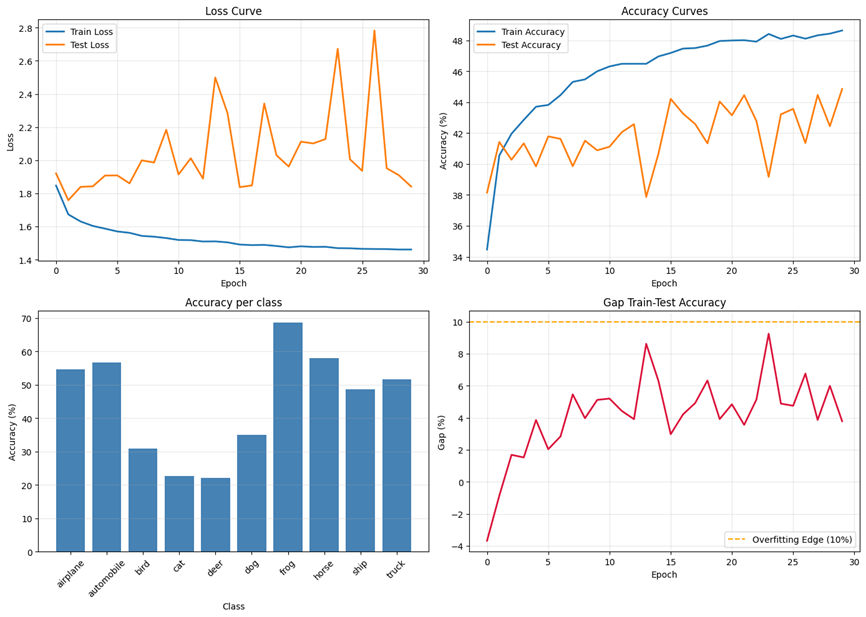












### Experiment 2: Larger Single Layer

|==================== MODEL ====================|

  * Architecture: [512]

  * Activation: relu
  * Optimizer: adam
  * Learning Rate: 0.001
  * Batch Size: 128
  * Epochs: 30
  * Dropout: 0
  * Weight Decay: 0

#

|==================== RESULTS ====================|

  * Final Train Accuracy: 48.41%

  * Final Test Accuracy: 36.92%
  * Best Test Accuracy: 42.95%
  * Training Duration: 609.75s (10.16 min)
  * Model Parameters: 1,578,506
  * Diagnosis: Underfitting


|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|

**TRAIN EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:       deer | Prediction:       deer | Probability: 28.82%
2. True: automobile | Prediction: automobile | Probability: 37.57%
3. True:       frog | Prediction:       frog | Probability: 92.38%
4. True:      horse | Prediction:      horse | Probability: 68.27%
5. True: automobile | Prediction: automobile | Probability: 50.96%

FALSE PREDICTIONS (TRAINING):
1. True:       bird | Prediction:      truck | Probability: 62.08%
2. True:        cat | Prediction:        dog | Probability: 57.48%
3. True:        cat | Prediction:      horse | Probability: 33.39%
4. True:        cat | Prediction:       deer | Probability: 26.51%
5. True:       deer | Prediction:       bird | Probability: 21.66%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:       ship | Prediction:       ship | Probability: 93.00%
2. True:       frog | Prediction:       frog | Probability: 77.04%
3. True:       frog | Prediction:       frog | Probability: 73.83%
4. True:      truck | Prediction:      truck | Probability: 100.00%
5. True:      horse | Prediction:      horse | Probability: 78.78%

FALSE PREDICTIONS (TEST):
1. True:        cat | Prediction:       ship | Probability: 78.81%
2. True:       ship | Prediction:      truck | Probability: 100.00%
3. True:   airplane | Prediction:       ship | Probability: 62.10%
4. True:       frog | Prediction:        cat | Probability: 45.55%
5. True: automobile | Prediction:        dog | Probability: 71.10%



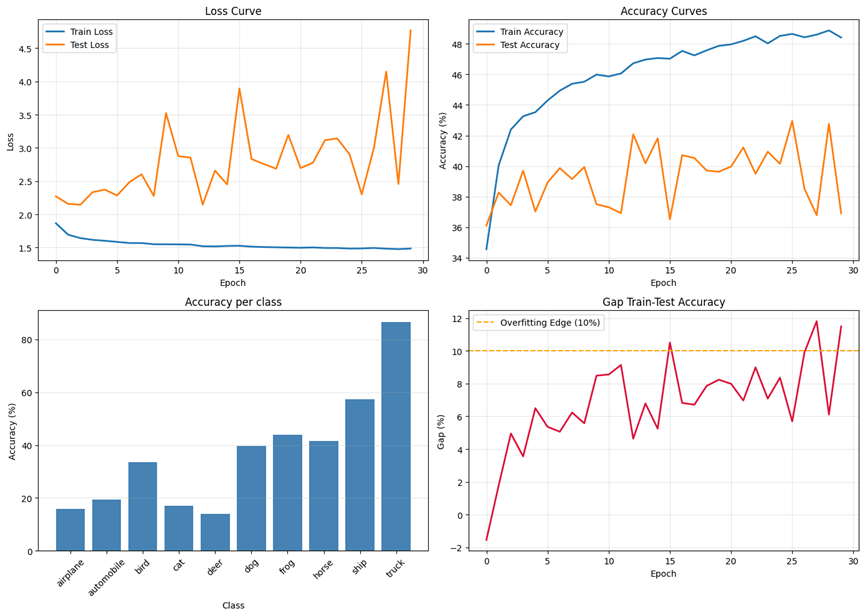




### Experiment 3: Two Hidden Layers

|==================== MODEL ====================|

  * Architecture: [512, 256]

  * Activation: relu
  * Optimizer: adam
  * Learning Rate: 0.001
  * Batch Size: 128
  * Epochs: 40
  * Dropout: 0
  * Weight Decay: 0

#

|==================== RESULTS ====================|


  * Final Train Accuracy: 55.95%

  * Final Test Accuracy: 47.92%
  * Best Test Accuracy: 48.50%
  * Training Duration: 810.80s (13.51 min)
  * Model Parameters: 1,707,274
  * Diagnosis: Underfitting

#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|

**TRAIN EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:        dog | Prediction:        dog | Probability: 69.82%
2. True:       frog | Prediction:       frog | Probability: 97.80%
3. True:       deer | Prediction:       deer | Probability: 82.96%
4. True:       ship | Prediction:       ship | Probability: 93.17%
5. True:      horse | Prediction:      horse | Probability: 71.05%

FALSE PREDICTIONS (TRAINING):
1. True:       bird | Prediction:        cat | Probability: 28.39%
2. True:       bird | Prediction:       deer | Probability: 35.93%
3. True:        cat | Prediction:      horse | Probability: 37.57%
4. True:      truck | Prediction:       ship | Probability: 66.45%
5. True:      truck | Prediction:   airplane | Probability: 41.44%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:        cat | Prediction:        cat | Probability: 54.68%
2. True:       ship | Prediction:       ship | Probability: 43.97%
3. True:       ship | Prediction:       ship | Probability: 87.04%
4. True:       frog | Prediction:       frog | Probability: 80.88%
5. True: automobile | Prediction: automobile | Probability: 45.82%

FALSE PREDICTIONS (TEST):
1. True:   airplane | Prediction:       deer | Probability: 68.61%
2. True:       frog | Prediction:        cat | Probability: 26.53%
3. True:        cat | Prediction:       deer | Probability: 15.67%
4. True: automobile | Prediction:      truck | Probability: 31.82%
5. True:      truck | Prediction:       ship | Probability: 33.70%



#

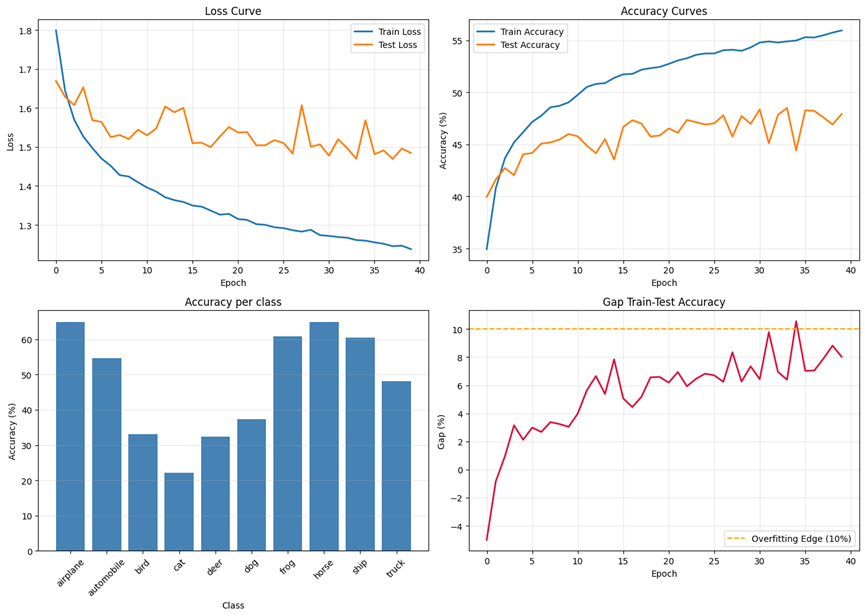

### **PHASE 2: REGULARIZATION TUNING**

In the second phase, we want to see the results when regularization is applied through weight decay while adjusting the dropout value each time. In the end, we conclude that, the stronger the regularization the less generalized are the results.
### Experiment 4: Add Weight Decay

|==================== MODEL ====================|

  * Architecture: [512, 256, 128]

  * Activation: relu
  * Optimizer: adam
  * Learning Rate: 0.001
  * Batch Size: 128
  * Epochs: 50
  * Dropout: 0.3
  * Weight Decay: 0.0001

#

|==================== RESULTS ====================|


  * Final Train Accuracy: 43.43%%

  * Final Test Accuracy: 46.55%%
  * Best Test Accuracy: 48.00%
  * Training Duration: 1928.75s (32.15 min)
  * Model Parameters: 1,738,890
  * Diagnosis: Underfitting

#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAINING EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:       ship | Prediction:       ship | Probability: 44.30%
2. True:       frog | Prediction:       frog | Probability: 46.82%
3. True:      horse | Prediction:      horse | Probability: 98.56%
4. True:        dog | Prediction:        dog | Probability: 66.15%
5. True: automobile | Prediction: automobile | Probability: 40.06%

FALSE PREDICTIONS (TRAINING):
1. True:       deer | Prediction:       frog | Probability: 33.92%
2. True:       bird | Prediction:       deer | Probability: 57.31%
3. True:        dog | Prediction:      horse | Probability: 68.82%
4. True:       frog | Prediction:        dog | Probability: 24.97%
5. True:       deer | Prediction:       frog | Probability: 43.12%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:        cat | Prediction:        cat | Probability: 30.64%
2. True:       ship | Prediction:       ship | Probability: 40.82%
3. True:       ship | Prediction:       ship | Probability: 36.03%
4. True:       frog | Prediction:       frog | Probability: 32.47%
5. True:       frog | Prediction:       frog | Probability: 28.94%

FALSE PREDICTIONS (TEST):
1. True:   airplane | Prediction:       ship | Probability: 45.35%
2. True: automobile | Prediction:        cat | Probability: 41.46%
3. True:        cat | Prediction:        dog | Probability: 23.63%
4. True:   airplane | Prediction:       ship | Probability: 34.44%
5. True:        dog | Prediction:       frog | Probability: 15.76%


    


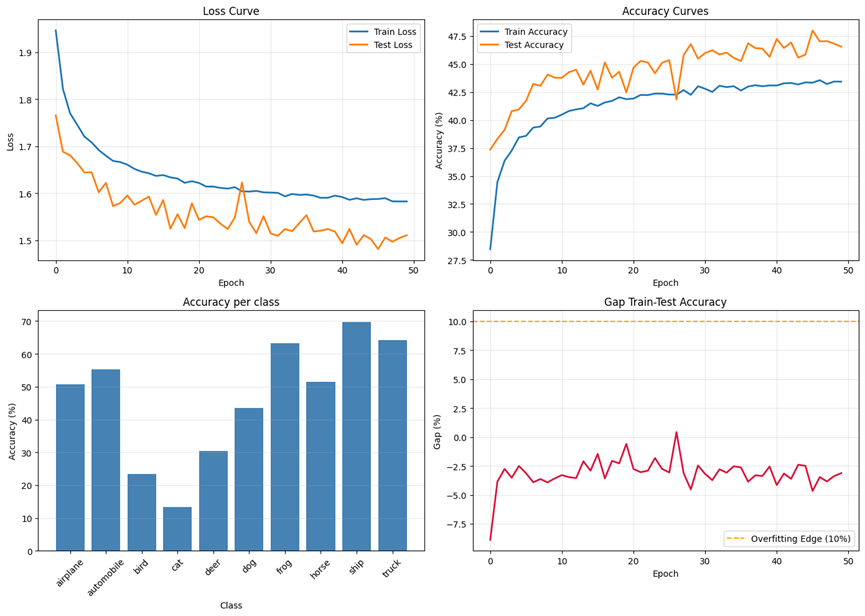


## Experiment 5: Stronger Regularization Test

|==================== MODEL ====================|

  * Architecture: [512, 256, 128]

  * Activation: relu
  * Optimizer: adam
  * Learning Rate: 0.001
  * Batch Size: 128
  * Epochs: 50
  * Dropout: 0.5
  * Weight Decay: 0.001

#
|==================== RESULTS ====================|

  * Final Train Accuracy: 32.33%

  * Final Test Accuracy: 37.82%
  * Best Test Accuracy: 40.20%
  * Training Duration: 1932.36s (32.21 min)
  * Model Parameters: 1,738,890
  * Diagnosis: Underfitting

#
|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAINING EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:       ship | Prediction:       ship | Probability: 50.45%
2. True:       frog | Prediction:       frog | Probability: 38.86%
3. True:       frog | Prediction:       frog | Probability: 22.76%
4. True:        dog | Prediction:        dog | Probability: 24.85%
5. True:       frog | Prediction:       frog | Probability: 18.28%

FALSE PREDICTIONS (TRAINING):
1. True:       bird | Prediction:       frog | Probability: 23.86%
2. True: automobile | Prediction:   airplane | Probability: 22.93%
3. True:       frog | Prediction: automobile | Probability: 17.23%
4. True:      horse | Prediction:      truck | Probability: 13.65%
5. True:      truck | Prediction: automobile | Probability: 28.72%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:       ship | Prediction:       ship | Probability: 38.38%
2. True:       frog | Prediction:       frog | Probability: 29.33%
3. True:       frog | Prediction:       frog | Probability: 24.07%
4. True:      truck | Prediction:      truck | Probability: 44.51%
5. True:        dog | Prediction:        dog | Probability: 14.05%

FALSE PREDICTIONS (TEST):
1. True:        cat | Prediction:      truck | Probability: 12.86%
2. True:       ship | Prediction:      truck | Probability: 36.87%
3. True:   airplane | Prediction:       ship | Probability: 27.41%
4. True:       frog | Prediction:        cat | Probability: 19.03%
5. True: automobile | Prediction:        dog | Probability: 21.26%

#

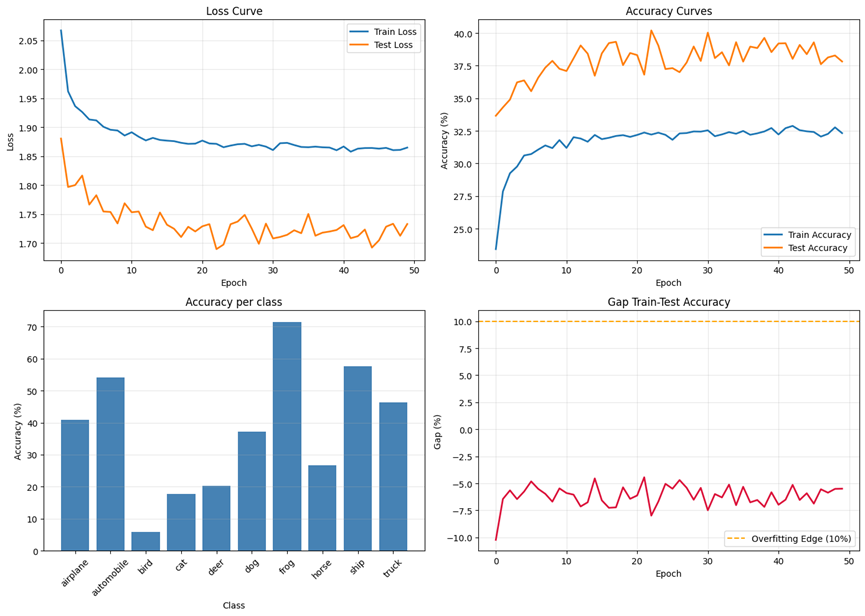

### **PHASE 3: ACTIVATION FUNCTIONS**

In this section, we aim to compare activation functions based on their affects on the model's results. We try out Leaky ReLU, tanh and sigmoid, and we do not include the ReLU function as it has shown a compelling performance so far from the previous models. We come to realize that the only one closest to ReLU's results is Leaky ReLU, as it was expected. So our best pick for activation is clearly ReLU.

### Experiment 6: Leaky ReLU

|==================== MODEL ====================|

* Architecture: [512, 256, 128]

* Activation: leaky relu

* Optimizer: adam

* Learning Rate: 0.001

* Batch Size: 128

* Epochs: 50

* Dropout: 0.3

* Weight Decay: 0.0001

#

|==================== RESULTS ====================|
  * Final Train Accuracy: 43.97%

  * Final Test Accuracy: 47.49%
  * Best Test Accuracy: 47.62%
  * Training Duration: 1993.29s (33.22 min)
  * Model Parameters: 1,738,890
  * Diagnosis: Underfitting

#
|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAINING EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:      horse | Prediction:      horse | Probability: 31.64%
2. True:       ship | Prediction:       ship | Probability: 82.04%
3. True:       frog | Prediction:       frog | Probability: 76.44%
4. True: automobile | Prediction: automobile | Probability: 45.94%
5. True:      truck | Prediction:      truck | Probability: 37.39%

FALSE PREDICTIONS (TRAINING):
1. True:       bird | Prediction:       deer | Probability: 22.41%
2. True: automobile | Prediction:   airplane | Probability: 24.31%
3. True:       frog | Prediction:       bird | Probability: 23.19%
4. True:      truck | Prediction: automobile | Probability: 44.47%
5. True:        cat | Prediction:   airplane | Probability: 22.37%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:        cat | Prediction:        cat | Probability: 22.70%
2. True:       ship | Prediction:       ship | Probability: 59.97%
3. True:       frog | Prediction:       frog | Probability: 54.98%
4. True: automobile | Prediction: automobile | Probability: 47.78%
5. True:       frog | Prediction:       frog | Probability: 45.17%

FALSE PREDICTIONS (TEST):
1. True:       ship | Prediction: automobile | Probability: 33.34%
2. True:   airplane | Prediction:       ship | Probability: 41.74%
3. True:       frog | Prediction:        cat | Probability: 32.12%
4. True:        cat | Prediction:       bird | Probability: 27.54%
5. True:      truck | Prediction: automobile | Probability: 44.28%



#

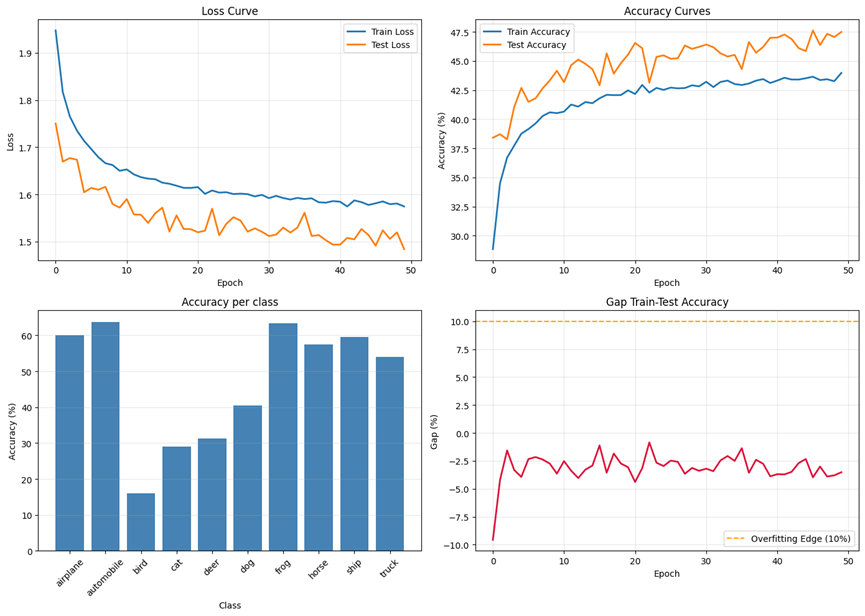



### Experiment 7: Tanh

|==================== MODEL ====================|

  * Architecture: [512, 256, 128]

  * Activation: tanh
  * Optimizer: adam
  * Learning Rate: 0.001
  * Batch Size: 128
  * Epochs: 50
  * Dropout: 0.3
  * Weight Decay: 0.0001

#

|==================== RESULTS ====================|

  * Final Train Accuracy: 36.34%
  * Final Test Accuracy: 37.99%

  * Best Test Accuracy: 38.59%
  * Training Duration: 1958.15s (32.64 min)
  * Model Parameters: 1,738,890
  * Diagnosis: Underfitting

#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAINING EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True: automobile | Prediction: automobile | Probability: 24.64%
2. True:      horse | Prediction:      horse | Probability: 51.61%
3. True:       ship | Prediction:       ship | Probability: 72.07%
4. True:       frog | Prediction:       frog | Probability: 50.94%
5. True: automobile | Prediction: automobile | Probability: 38.07%

FALSE PREDICTIONS (TRAINING):
1. True:       bird | Prediction:       deer | Probability: 31.08%
2. True:       frog | Prediction:       bird | Probability: 26.52%
3. True:      truck | Prediction: automobile | Probability: 57.91%
4. True:        cat | Prediction:   airplane | Probability: 61.13%
5. True:   airplane | Prediction:       ship | Probability: 46.86%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:        cat | Prediction:        cat | Probability: 22.91%
2. True:       ship | Prediction:       ship | Probability: 47.91%
3. True: automobile | Prediction: automobile | Probability: 30.69%
4. True: automobile | Prediction: automobile | Probability: 43.30%
5. True:      truck | Prediction:      truck | Probability: 42.79%

FALSE PREDICTIONS (TEST):
1. True:       ship | Prediction: automobile | Probability: 44.69%
2. True:   airplane | Prediction:       ship | Probability: 43.54%
3. True:       frog | Prediction:       deer | Probability: 42.43%
4. True:       frog | Prediction: automobile | Probability: 24.29%
5. True:       frog | Prediction:       deer | Probability: 32.31%


#

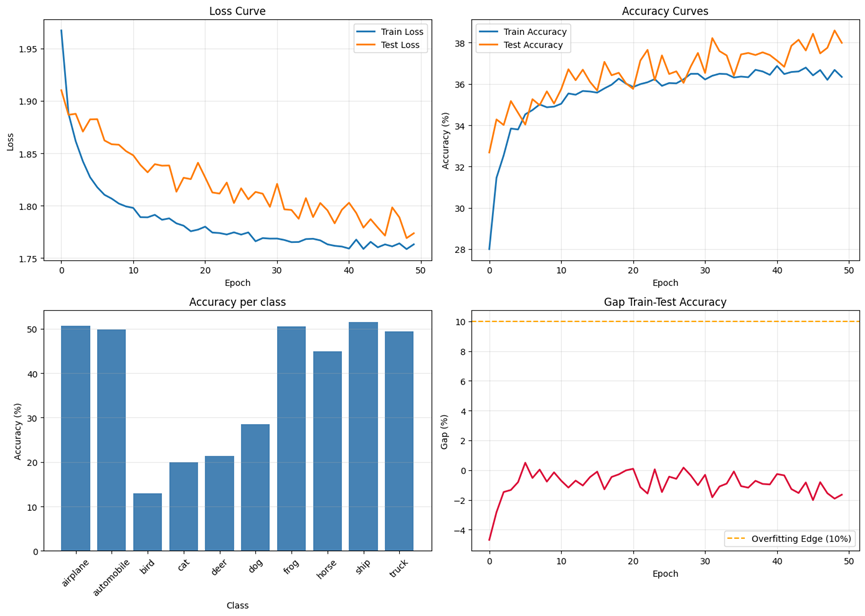

### Experiment 8: Sigmoid

|==================== MODEL ====================|
  * Architecture: [512, 256, 128]

  * Activation: sigmoid
  * Optimizer: adam
  * Learning Rate: 0.001
  * Batch Size: 128
  * Epochs: 50
  * Dropout: 0.3
  * Weight Decay: 0.0001


#

|==================== RESULTS ====================|
  * Final Train Accuracy: 40.34%
  * Final Test Accuracy: 40.97%
  * Best Test Accuracy: 41.10%
  * Training Duration: 2000.51s (33.34 min)
  * Model Parameters: 1,738,890

  * Diagnosis: Underfitting

#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAINING EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:       bird | Prediction:       bird | Probability: 20.86%
2. True: automobile | Prediction: automobile | Probability: 28.08%
3. True:      horse | Prediction:      horse | Probability: 33.90%
4. True:       ship | Prediction:       ship | Probability: 70.48%
5. True:       frog | Prediction:       frog | Probability: 51.07%

FALSE PREDICTIONS (TRAINING):
1. True:       frog | Prediction:       bird | Probability: 26.64%
2. True:      truck | Prediction: automobile | Probability: 50.96%
3. True:        cat | Prediction:   airplane | Probability: 41.48%
4. True:   airplane | Prediction:       ship | Probability: 17.37%
5. True:      horse | Prediction:        cat | Probability: 22.80%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:       frog | Prediction:       frog | Probability: 32.46%
2. True: automobile | Prediction: automobile | Probability: 44.94%
3. True:   airplane | Prediction:   airplane | Probability: 42.24%
4. True:       ship | Prediction:       ship | Probability: 65.69%
5. True:        dog | Prediction:        dog | Probability: 30.81%

FALSE PREDICTIONS (TEST):
1. True:        cat | Prediction: automobile | Probability: 39.75%
2. True:       ship | Prediction:      truck | Probability: 44.76%
3. True:       ship | Prediction:      truck | Probability: 37.61%
4. True:   airplane | Prediction:       ship | Probability: 40.70%
5. True:       frog | Prediction:       deer | Probability: 45.65%



#

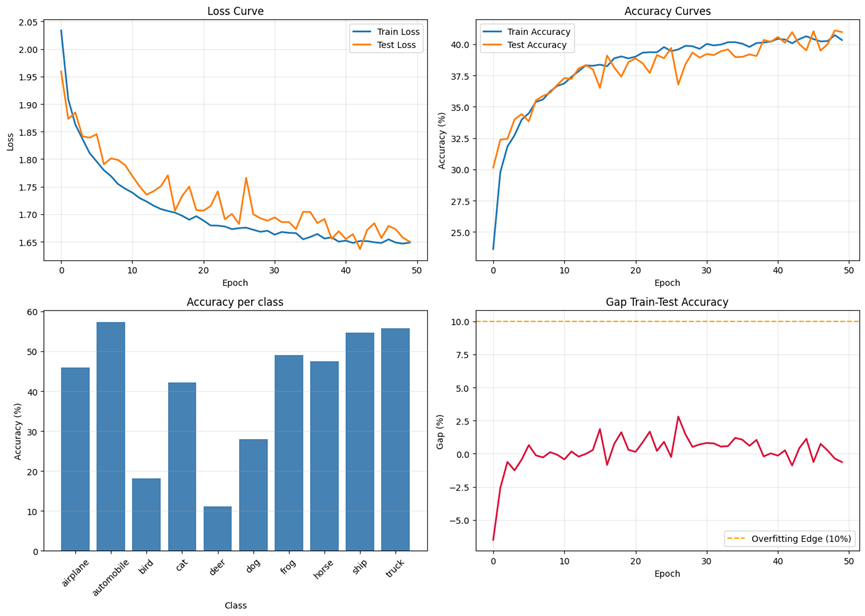

### **PHASE 4: OPTIMIZER COMPARISON**

In the specific phase, we conduct experiments based on the same set of hypermarameters' values except for the optimizers, and for that to compare how effective each of them is. In the end we can see that sgd with momentum is far better than the RMSProp, and additionaly we saw from the previous examples that the adam optimizer is a fair good one, which is the reason we skipped to include it in this phase. So we conclude sgd(+ momentum) and adam are by far our best picks.

### Experiment 9: SGD with Momentum

|==================== MODEL ====================|

  * Architecture: [512, 256, 128]
  * Activation: relu

  * Optimizer: sgd
  * Momentum: 0.9
  * Learning Rate: 0.01
  * Batch Size: 128
  * Epochs: 60
  * Dropout: 0.3
  * Weight Decay: 0.0001

#

|==================== RESULTS ====================|


  * Final Train Accuracy: 50.99%
  * Final Test Accuracy: 52.85%
  * Best Test Accuracy: 52.85%

  * Training Duration: 2184.74s (36.41 min)
  * Model Parameters: 1,738,890
  * Diagnosis: Underfitting

#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAINING EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:        dog | Prediction:        dog | Probability: 46.96%
2. True:       deer | Prediction:       deer | Probability: 25.87%
3. True:        cat | Prediction:        cat | Probability: 50.23%
4. True:       frog | Prediction:       frog | Probability: 57.46%
5. True:   airplane | Prediction:   airplane | Probability: 84.50%

FALSE PREDICTIONS (TRAINING):
1. True:      truck | Prediction:      horse | Probability: 38.80%
2. True:       ship | Prediction:      truck | Probability: 32.06%
3. True:   airplane | Prediction: automobile | Probability: 51.93%
4. True:   airplane | Prediction:       deer | Probability: 35.24%
5. True:   airplane | Prediction:      horse | Probability: 23.47%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:        cat | Prediction:        cat | Probability: 53.43%
2. True:       ship | Prediction:       ship | Probability: 52.32%
3. True:       ship | Prediction:       ship | Probability: 48.96%
4. True:       frog | Prediction:       frog | Probability: 59.62%
5. True:       frog | Prediction:       frog | Probability: 76.10%

FALSE PREDICTIONS (TEST):
1. True:   airplane | Prediction:       ship | Probability: 53.13%
2. True:       frog | Prediction:        cat | Probability: 30.27%
3. True: automobile | Prediction:        cat | Probability: 47.03%
4. True:        cat | Prediction:        dog | Probability: 21.38%
5. True:      truck | Prediction: automobile | Probability: 50.10%

#

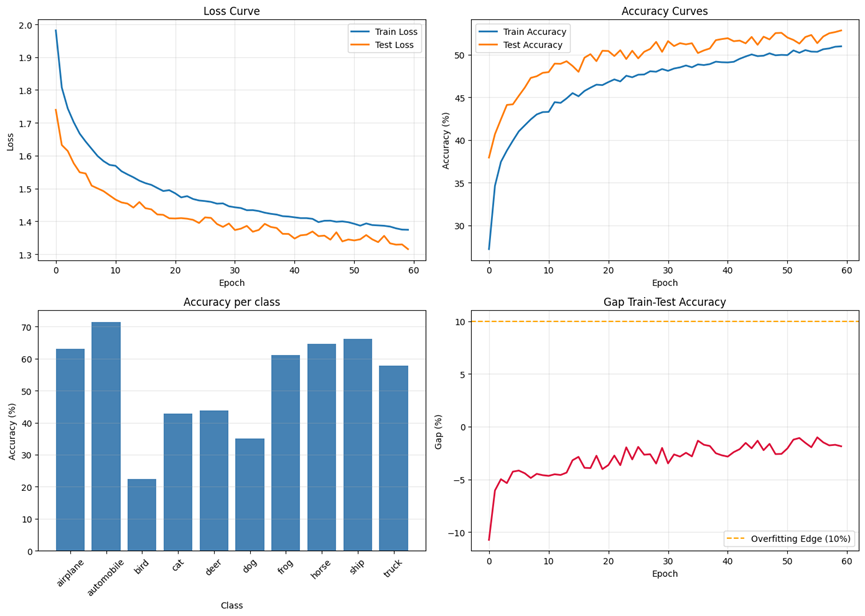

### Experiment 10: RMSProp

|==================== MODEL ====================|

  * Architecture: [512, 256, 128]
  * Activation: relu
  * Optimizer: rmsprop
  * Learning Rate: 0.01
  * Batch Size: 128
  * Epochs: 60
  * Dropout: 0.3

  * Weight Decay: 0.0001

#

|==================== RESULTS ====================|

  * Final Train Accuracy: 9.97%
  * Final Test Accuracy: 10.00%
  * Best Test Accuracy: 10.16%
  * Training Duration: 2626.21s (43.77 min)
  * Model Parameters: 1,738,890

  * Diagnosis: Underfitting


#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|

**TRAINING EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:        cat | Prediction:        cat | Probability: 10.49%
2. True:        cat | Prediction:        cat | Probability: 10.49%
3. True:        cat | Prediction:        cat | Probability: 10.49%
4. True:        cat | Prediction:        cat | Probability: 10.49%
5. True:        cat | Prediction:        cat | Probability: 10.49%

FALSE PREDICTIONS (TRAINING):
1. True:      truck | Prediction:        cat | Probability: 10.49%
2. True:       ship | Prediction:        cat | Probability: 10.49%
3. True:      truck | Prediction:        cat | Probability: 10.49%
4. True: automobile | Prediction:        cat | Probability: 10.49%
5. True:      horse | Prediction:        cat | Probability: 10.49%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:        cat | Prediction:        cat | Probability: 10.49%
2. True:        cat | Prediction:        cat | Probability: 10.49%
3. True:        cat | Prediction:        cat | Probability: 10.49%
4. True:        cat | Prediction:        cat | Probability: 10.49%
5. True:        cat | Prediction:        cat | Probability: 10.49%

FALSE PREDICTIONS (TEST):
1. True:       ship | Prediction:        cat | Probability: 10.49%
2. True:       ship | Prediction:        cat | Probability: 10.49%
3. True:   airplane | Prediction:        cat | Probability: 10.49%
4. True:       frog | Prediction:        cat | Probability: 10.49%
5. True:       frog | Prediction:        cat | Probability: 10.49%


#


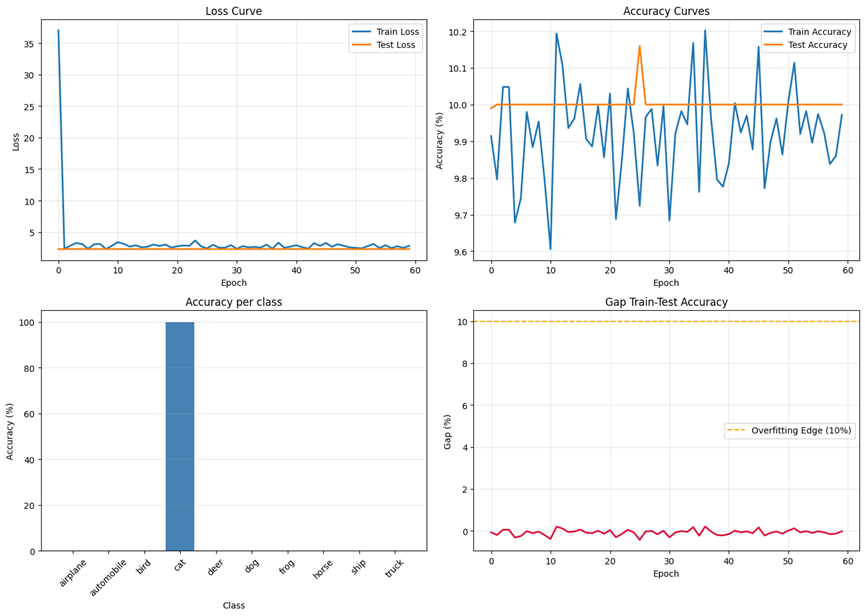


### **PHASE 5: ROAD TO OPTIMIZED MODEL**

In this last phase, we have concluded and observed which are the best choices, from the previous experiments, when it comes to model architecture (multiple hiden layers), activation functions (relu), optimizers (adam(somewhat better), sgd), learning rates (0.01, 0.001, 0.0001), batch sizes (64, 128), epochs (50, 60), dropout(0, 0.3) and weight decay (0, 0.0001). So the best generalization model with a diagnosed good fitting must derive from a combination of those values. We begin with a certain set of values and change them accordingly.

### Experiment 11

|==================== MODEL ====================|

  * Architecture: [1024, 512, 256]
  * Activation: relu
  * Optimizer: sgd
  * Momentum: 0.9
  * Learning Rate: 0.01

  * Batch Size: 128
  * Epochs: 60
  * Dropout: 0.3
  * Weight Decay: 0.0001

#

|==================== RESULTS ====================|


  * Final Train Accuracy: 54.30%

  * Final Test Accuracy: 54.64%
  * Best Test Accuracy: 54.91%
  * Training Duration: 1129.65s (18.83 min)
  * Model Parameters: 3,805,450
  * Diagnosis: Underfitting

#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAINING EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:      horse | Prediction:      horse | Probability: 50.61%
2. True:      truck | Prediction:      truck | Probability: 81.42%
3. True:       bird | Prediction:       bird | Probability: 43.46%
4. True:       ship | Prediction:       ship | Probability: 68.33%
5. True:       deer | Prediction:       deer | Probability: 42.94%

FALSE PREDICTIONS (TRAINING):
1. True:   airplane | Prediction:       bird | Probability: 43.34%
2. True:       deer | Prediction:       bird | Probability: 60.04%
3. True:       bird | Prediction:       deer | Probability: 57.18%
4. True:       deer | Prediction:       bird | Probability: 36.51%
5. True:        cat | Prediction:        dog | Probability: 50.19%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:       ship | Prediction:       ship | Probability: 45.11%
2. True:       ship | Prediction:       ship | Probability: 45.25%
3. True:       frog | Prediction:       frog | Probability: 62.59%
4. True: automobile | Prediction: automobile | Probability: 44.02%
5. True:       frog | Prediction:       frog | Probability: 64.62%

FALSE PREDICTIONS (TEST):
1. True:        cat | Prediction:        dog | Probability: 27.63%
2. True:   airplane | Prediction:       ship | Probability: 39.18%
3. True:       frog | Prediction:        cat | Probability: 25.47%
4. True:   airplane | Prediction:       ship | Probability: 35.28%
5. True:        dog | Prediction:        cat | Probability: 23.89%


#

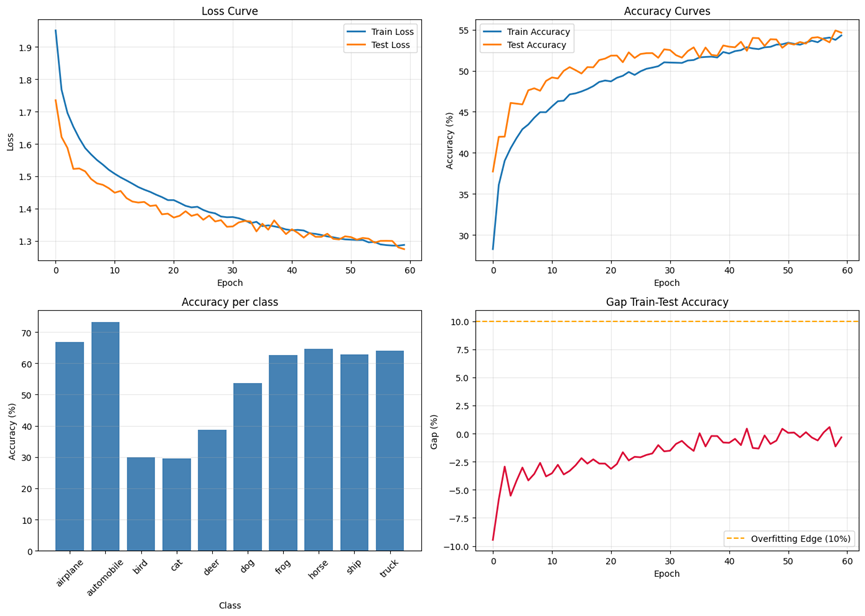





### Experiment 12

|==================== MODEL ====================|

  * Architecture: [1024, 512, 256]

  * Activation: relu
  * Optimizer: sgd
  *	Momentum: 0.9
  * Learning Rate: 0.001
  * Batch Size: 64
  * Epochs: 50
  * Dropout: 0
  * Weight Decay: 0

#

|==================== RESULTS ====================|

  * Final Train Accuracy: 59.93%

  * Final Test Accuracy: 56.30%
  * Best Test Accuracy: 56.45%
  * Training Duration: 1127.07s (18.78 min)
  * Model Parameters: 3,805,450
  * Diagnosis: Good Fitting

#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAIN EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:        cat | Prediction:        cat | Probability: 41.63%
2. True:      horse | Prediction:      horse | Probability: 60.17%
3. True:      horse | Prediction:      horse | Probability: 89.58%
4. True: automobile | Prediction: automobile | Probability: 65.58%
5. True:      truck | Prediction:      truck | Probability: 60.73%

FALSE PREDICTIONS (TRAINING):
1. True: automobile | Prediction:      truck | Probability: 87.97%
2. True:       deer | Prediction:       ship | Probability: 43.32%
3. True:   airplane | Prediction:       ship | Probability: 51.64%
4. True:       frog | Prediction:        dog | Probability: 36.59%
5. True:      truck | Prediction:      horse | Probability: 64.05%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:        cat | Prediction:        cat | Probability: 44.82%
2. True:       ship | Prediction:       ship | Probability: 91.09%
3. True:       ship | Prediction:       ship | Probability: 69.88%
4. True:   airplane | Prediction:   airplane | Probability: 56.61%
5. True:       frog | Prediction:       frog | Probability: 75.00%

FALSE PREDICTIONS (TEST):
1. True:       frog | Prediction:        cat | Probability: 39.19%
2. True: automobile | Prediction:        cat | Probability: 45.50%
3. True:        cat | Prediction:        dog | Probability: 38.45%
4. True:      horse | Prediction:        dog | Probability: 40.09%
5. True:       ship | Prediction:       frog | Probability: 35.78%


#

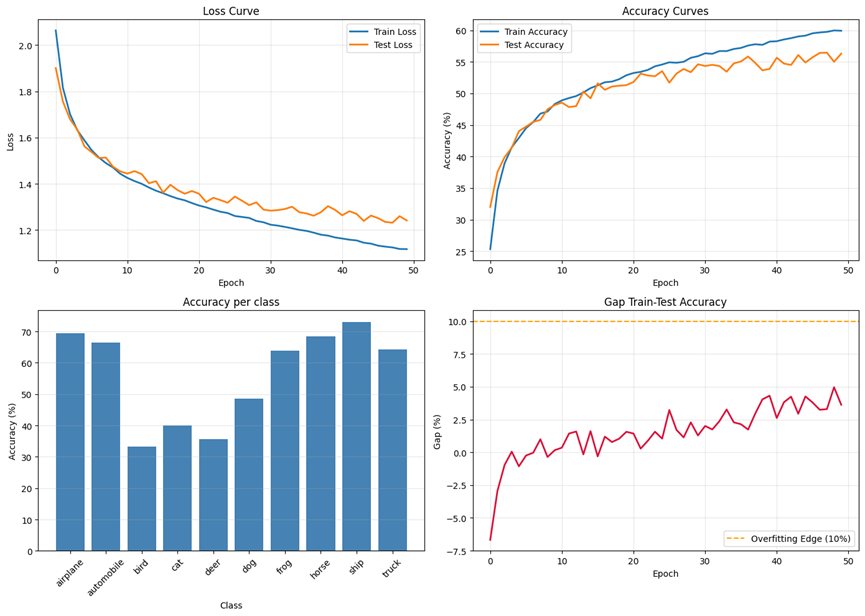


### Experiment 13

|==================== MODEL ====================|

  * Architecture: [1024, 512, 256]
  * Activation: relu
  * Optimizer: adam
  * Learning Rate: 0.0001
  * Batch Size: 64
  * Epochs: 50
  * Dropout: 0

  * Weight Decay: 0.001

#

|==================== RESULTS ====================|

  * Final Train Accuracy: 61.53%

  * Final Test Accuracy: 54.49%
  * Best Test Accuracy: 57.06%
  * Training Duration: 1134.28s (18.90 min)
  * Model Parameters: 3,805,450
  * Diagnosis: Good Fitting

#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAINING EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:       deer | Prediction:       deer | Probability: 72.37%
2. True:      horse | Prediction:      horse | Probability: 97.24%
3. True: automobile | Prediction: automobile | Probability: 78.89%
4. True:   airplane | Prediction:   airplane | Probability: 46.67%
5. True:      truck | Prediction:      truck | Probability: 85.84%

FALSE PREDICTIONS (TRAINING):
1. True:        cat | Prediction:        dog | Probability: 37.47%
2. True: automobile | Prediction:      truck | Probability: 88.43%
3. True:      horse | Prediction:       frog | Probability: 26.90%
4. True:       frog | Prediction:        dog | Probability: 43.75%
5. True:      truck | Prediction:      horse | Probability: 74.37%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:        cat | Prediction:        cat | Probability: 48.90%
2. True:       ship | Prediction:       ship | Probability: 93.16%
3. True:       ship | Prediction:       ship | Probability: 64.77%
4. True:   airplane | Prediction:   airplane | Probability: 74.44%
5. True:       frog | Prediction:       frog | Probability: 84.17%

FALSE PREDICTIONS (TEST):
1. True:       frog | Prediction:        cat | Probability: 34.67%
2. True: automobile | Prediction:        cat | Probability: 38.52%
3. True:       ship | Prediction:        dog | Probability: 25.84%
4. True:        dog | Prediction:        cat | Probability: 49.38%
5. True:      horse | Prediction:      truck | Probability: 41.36%



#

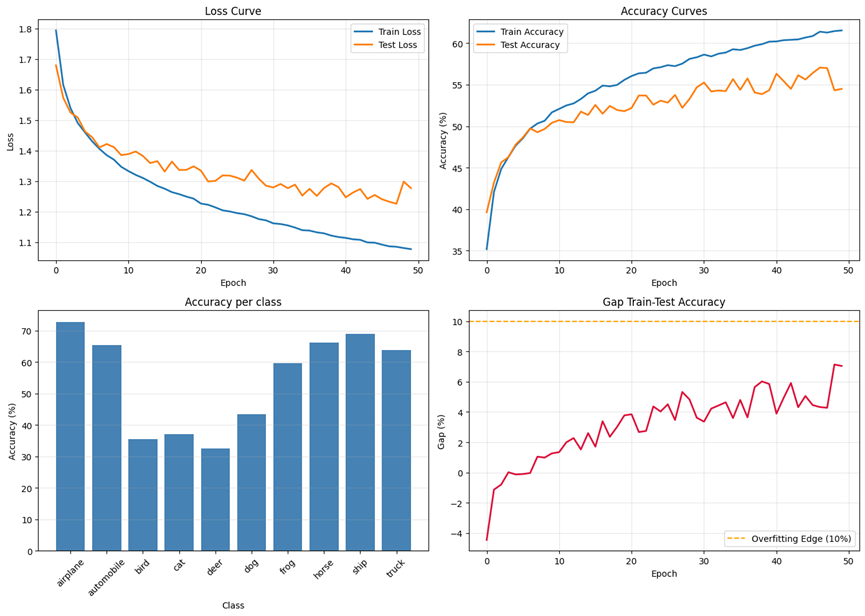

### Experiment 14

|==================== MODEL ====================|

  * Architecture: [1024, 512, 256]

  * Activation: relu
  * Optimizer: adam
  * Learning Rate: 0.0001
  * Batch Size: 128
  * Epochs: 50
  * Dropout: 0
  * Weight Decay: 0

#

|==================== RESULTS ====================|

  * Final Train Accuracy: 65.06%

  * Final Test Accuracy: 56.52%
  * Best Test Accuracy: 57.00%
  * Training Duration: 1035.38s (17.26 min)
  * Model Parameters: 3,805,450
  * Diagnosis: Good Fitting

#

|==================== EXAMPLES OF CORRECT AND FALSE CLASSIFICATIONS ====================|


**TRAIN EXAMPLES**

CORRECT PREDICTIONS (TRAINING):
1. True:        cat | Prediction:        cat | Probability: 33.49%
2. True:       deer | Prediction:       deer | Probability: 40.98%
3. True:      horse | Prediction:      horse | Probability: 42.35%
4. True:      horse | Prediction:      horse | Probability: 97.76%
5. True: automobile | Prediction: automobile | Probability: 96.51%

FALSE PREDICTIONS (TRAINING):
1. True: automobile | Prediction:      truck | Probability: 91.34%
2. True:   airplane | Prediction:       ship | Probability: 49.70%
3. True:       frog | Prediction:        dog | Probability: 36.00%
4. True:      truck | Prediction:      horse | Probability: 80.19%
5. True:       deer | Prediction:        cat | Probability: 24.96%

**TEST EXAMPLES**

CORRECT PREDICTIONS (TEST):
1. True:        cat | Prediction:        cat | Probability: 62.30%
2. True:       ship | Prediction:       ship | Probability: 97.40%
3. True:   airplane | Prediction:   airplane | Probability: 63.18%
4. True:       frog | Prediction:       frog | Probability: 82.56%
5. True:       frog | Prediction:       frog | Probability: 52.03%

FALSE PREDICTIONS (TEST):
1. True:       ship | Prediction:   airplane | Probability: 37.81%
2. True:       frog | Prediction:        cat | Probability: 40.33%
3. True: automobile | Prediction:      truck | Probability: 45.97%
4. True:        cat | Prediction:        dog | Probability: 36.29%
5. True:      truck | Prediction: automobile | Probability: 55.04%


#

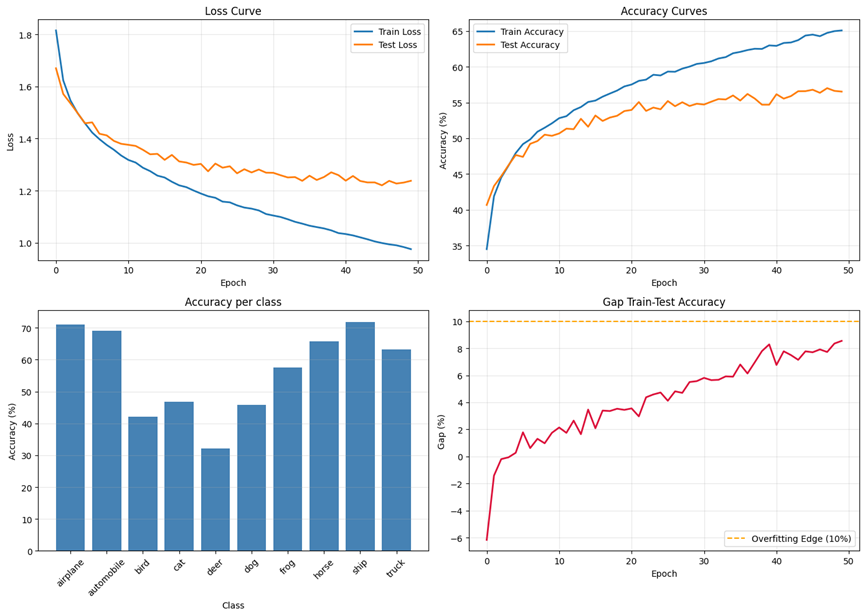



## **11\. Comparison Between K-NN, NCC and MLP**

**Results Summary**


* Accuracy: NCC -> [28.12%] |------| KNN(K=1) -> [35.67%] |------| KNN(K=3) -> [35.49%] |------| MLP(1024, 512, 256) -> [56.52%]

* F1-Score: NCC -> [0.259] |------| KNN(K=1) -> [0.352] |------| KNN(K=3) -> [0.348] |------| MLP(1024, 512, 256) -> [0.57]

* Time: NCC -> [1.1 sec] |------| KNN(K=1) -> [109 min] |------| KNN(K=3) -> [109 min] |------| MLP(1024, 512, 256) -> [17 min]



**Key Findings**

Accuracy Winner: MLP (56.52%), because:


*   1.59× better than KNN (35.67%)

*   2.01× better than NCC (28.12%)

* +20.85% improvement over best classical method


#

**Speed Comparison**



*   NCC: Fastest (1 sec) but lowest accuracy

*   MLP: Moderate training (17 min), then fast inference
*  KNN: Slowest (109 min) - 583× slower than MLP for worse accuracy

#


**Why MLP Wins**



*   Learns features automatically through 3.8M parameters

*   Non-linear transformations capture complex patterns
*  Hierarchical representations (1024→512→256 neurons)
*  Good generalization: 65% train, 57% test (8% gap)



**Why Classical Methods Fail**


*   NCC: Oversimplified (only 10 class centroids)

*   KNN: No feature learning, curse of dimensionality in 3,072D space

*  Both: Can't discover semantic patterns in raw pixels

*  Both: Can't discover semantic patterns in raw pixels



**Practical Implications**

KNN is impractical:

*  109 minutes for predictions with only 36% accuracy

*  Doesn't scale with larger datasets

MLP offers best value:

*  One-time 17-min training cost

*  56% accuracy (near 2× better than alternatives)

*  Fast inference after training

*  Room for improvement (CNN, dropout, augmentation → 70%+)


**Final Verdict**

MLP is the clear winner for CIFAR-10:

*  1.59× more accurate than KNN

*  583× faster than KNN at inference
*  Scalable and production-ready

The 17-minute training investment delivers a model that significantly outperforms classical methods in both accuracy and practical deployment.

**Conclusion**: The MLP demonstrates why a feedforward neural network is a better option than classical methods classification, that is superior accuracy with reasonable computational cost.